In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from cvxopt import matrix, solvers
import math
import matplotlib.pyplot as plt
from utils import *
from class_utils import *
from scipy.spatial.distance import cdist 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_classification
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from collections import defaultdict
from random import sample
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.metrics import pairwise_distances
from tqdm import trange, tqdm

from scipy import stats

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import *
from class_utils import *

import Orange
#from orangecontrib.spectroscopy import data
from Orange.data.io import FileFormat
#import Orange.data.io.FileFormat.read_spectra as read_spectra

In [3]:
def read_spectra(self):
        channels = self.get_channels()

        for c, label in channels.items():
            if label.decode("utf-8") == self.sheet:
                self.data_signal = c
                break
        else:
            self.data_signal = list(channels.keys())[0]

        import h5py
        hdf5_file = h5py.File(self.filename,'r')
        keys = list(hdf5_file.keys())

        hyperspectra = False
        intensities = []
        wavenumbers = []
        x_locs = []
        y_locs = []

        # load measurements
        for meas_name in filter(lambda s: s.startswith('Measurement'), keys):
            hdf5_meas = hdf5_file[meas_name]

            meas_keys = list(hdf5_meas.keys())
            meas_attrs = hdf5_meas.attrs

            # check if this measurement contains the selected data channel
            selected_signal = False
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                if hdf5_chan.attrs.keys().__contains__('DataSignal') and hdf5_chan.attrs['DataSignal'] == self.data_signal:
                    selected_signal = True
                    break
            if not selected_signal:
                continue

            # build range arrays
            spec_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeWavenumberStart'):
                    wn_start = meas_attrs['RangeWavenumberStart'][0]
                    wn_end = meas_attrs['RangeWavenumberEnd'][0]
                    wn_points = meas_attrs['RangeWavenumberPoints'][0]
                    spec_vals = np.linspace(wn_start, wn_end, wn_points)
            except:
                raise IOError("Error reading wavenumber range from " + self.filename)

            pos_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeXStart'):
                    x_start = meas_attrs['RangeXStart'][0]
                    x_points = meas_attrs['RangeXPoints'][0]
                    x_incr = meas_attrs['RangeXIncrement'][0]
                    x_end = x_start + x_incr * (x_points - 1)
                    x_min = min(x_start, x_end)
                    if meas_attrs.keys().__contains__('RangeYStart'):
                        y_start = meas_attrs['RangeYStart'][0]
                        y_points = meas_attrs['RangeYPoints'][0]
                        y_incr = meas_attrs['RangeYIncrement'][0]
                        y_end = y_start + y_incr * (y_points - 1)
                        y_min = min(y_start, y_end)

                        # construct the positions array
                        for iY in range(int(y_points)):
                            y = y_min + iY * abs(y_incr)
                            for iX in range(int(x_points)):
                                x = x_min + iX * abs(x_incr)
                                pos_vals.append([x, y])
                        pos_vals = np.array(pos_vals)
                else:
                    pos_vals = np.array([1])
            except:
                raise IOError("Error reading position data from " + self.filename)

            hyperspectra = pos_vals.shape[0] > 1

            # ignore backgrounds and unchecked data
            if not hyperspectra:
                if meas_attrs.keys().__contains__('IsBackground') and meas_attrs['IsBackground'][0]:
                    continue
                if meas_attrs.keys().__contains__('Checked') and not meas_attrs['Checked'][0]:
                    continue

            if len(wavenumbers) == 0:
                wavenumbers = spec_vals

            if hyperspectra:
                x_len = meas_attrs['RangeXPoints'][0]
                y_len = meas_attrs['RangeYPoints'][0]
                x_locs = pos_vals[:x_len,0]
                y_indices = np.round(np.linspace(0, pos_vals.shape[0] - 1, y_len)).astype(int)
                y_locs = pos_vals[y_indices,1]
            else:
                x_locs.append(meas_attrs['LocationX'][0])
                y_locs.append(meas_attrs['LocationY'][0])

            # load channels
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                chan_attrs = hdf5_chan.attrs

                signal = chan_attrs['DataSignal']
                if signal != self.data_signal:
                    continue

                data = hdf5_chan['Raw_Data']
                if hyperspectra:
                    rows = meas_attrs['RangeYPoints'][0]
                    cols = meas_attrs['RangeXPoints'][0]
                    intensities = np.reshape(data, (rows,cols,data.shape[1])) # organized rows, columns, wavelengths
                    break
                else:
                    intensities.append(data[0,:])

        #intensities = np.array(intensities)
        #features = np.array(wavenumbers)
        intensities = intensities
        features = np.array(wavenumbers)
        x_locs = np.array(x_locs).flatten()
        y_locs = np.array(y_locs).flatten()
        if hyperspectra:
            return _spectra_from_image(intensities, features, x_locs, y_locs)
        else:
            spectra = intensities

            # locations
            x_loc = y_loc = np.arange(len(spectra))
            metas = np.array([x_locs[x_loc], y_locs[y_loc]]).T

            domain = Orange.data.Domain([], None,
                                        metas=[Orange.data.ContinuousVariable.make("map_x"),
                                               Orange.data.ContinuousVariable.make("map_y")]
                                        )
            data = Orange.data.Table.from_numpy(domain, X=np.zeros((len(spectra), 0)),
                                                metas=np.asarray(metas, dtype=object))
            return features, spectra, data
        
Orange.data.io.FileFormat.read_spectra = read_spectra


In [4]:
#absolute_filename = FileFormat.locate('OPTIR/MEC_02_066_Daycroft_AlSI_1_051023_06072023_Run1.ptir')
absolute_filename = FileFormat.locate('OPTIR/MEC_02_068_FHS_AlSI_1_051023_06072023_Run1.ptir')
reader = FileFormat.get_reader(absolute_filename)
spectra = read_spectra(reader)

MissingReaderException: No readers for file "OPTIR/MEC_02_068_FHS_AlSI_1_051023_06072023_Run1.ptir"

In [164]:
spectra_data = pd.DataFrame(spectra[1])
spectra_data = spectra_data.drop(1).reset_index(drop=True)
spectra_data.columns = spectra[0]
#spectra_data = spectra_data.loc[:, ~np.isnan(spectra_data.iloc[0,:])]
#spectra_data = spectra_data.to_numpy()
#spectra_data = ((spectra_data - spectra_data.mean(1)[:, None]) / spectra_data.std(1)[:, None])
spectra_data_bg = spectra_data.loc[:, ~np.isnan(spectra_data.iloc[0,:])]

In [165]:
background_data = pd.read_csv('OPTIR/MEC_02_068_FHS_AlSI_1_051023_06072023_Run1_Al-Si_background.csv')
#background_data = background_data.set_index('X value [cm⁻¹]').T.reset_index(drop=True)
background_data.columns = [i for i in range(28)]
background_data = background_data.set_index(0).T.reset_index(drop=True)
background_data = background_data.to_numpy()
#background_data = (background_data - background_data.mean(1)[:,None]) / background_data.std(1)[:,None]
background_data = np.float32(background_data)

In [166]:
df_library = pd.read_csv('spectral_data_all.csv')
df_library.drop(columns=['Unnamed: 0'], inplace=True)
df_flopp = df_library.query('data_source == "flopp" or data_source == "flopp_e"').reset_index(drop=True)
df_flopp = df_flopp.query('intensity > 0')
df_flopp = norm_spect(df_flopp, norm_type='SNV')
df_flopp_pivot = df_flopp.pivot(index=['file_name', 'polymer', 'data_source'], 
               columns='wavelength', 
               values='intensity').reset_index()
wl_list = df_flopp_pivot.columns[3:]
#df_flopp_pivot.columns = list(df_flopp_pivot.columns[:3]) + ['wl_' + str(round(x*100)) for x in df_flopp_pivot.columns[3:]]
polymer_list = df_flopp_pivot['polymer'].drop_duplicates().to_numpy()


#X_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,3:].reset_index(drop=True)
X_train = df_flopp_pivot.iloc[:,3:].reset_index(drop=True)

X_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,3:].reset_index(drop=True)
#y_train = df_flopp_pivot.query('data_source == "flopp"').iloc[:,1].reset_index(drop=True)
y_train = df_flopp_pivot.iloc[:,1].reset_index(drop=True)

y_test = df_flopp_pivot.query('data_source == "flopp_e"').iloc[:,1].reset_index(drop=True)

idx_range = np.logical_or(
    np.logical_and(
        wl_list > (spectra_data.columns[1:]).min(),
        wl_list < (spectra_data.columns[1:].to_numpy()[np.where(np.isnan(spectra_data.iloc[0,:]))]).min()-3, #-1
    ),
    np.logical_and(
        wl_list > (spectra_data.columns[1:].to_numpy()[np.where(np.isnan(spectra_data.iloc[0,:]))]).max()+1,
        wl_list < (spectra_data.columns[1:]).max(),
    )
)


# construct folds: -----------------------------------------------------------
idx = sample(range(y_train.shape[0]), y_train.shape[0])
X_train = X_train.reset_index(drop=True)
X_train_ = X_train.copy()
y_train = y_train.reset_index(drop=True)
X_train_['fold'] = np.array(idx) // (X_train_.shape[0]/10)
folds_size = pd.DataFrame(X_train_.groupby('fold').size())
folds_size.columns = ['Size']
#display(folds_size)

# folds as array indices
folds = []
n = y_train.shape[0]
rows = np.arange(n)
for fold in range(10):
    train = np.asarray(X_train_['fold'] != fold).nonzero()[0]
    test = np.asarray(X_train_['fold'] == fold).nonzero()[0]
    folds.append((train, test))
    
x_train = X_train.to_numpy()
y_train_ = y_train.to_numpy()
y_train_[y_train_ == 'Nylon'] = 'Polyamide'
y_train_[y_train_ == 'Polyester'] = 'Polyethylene Terephthalate'

x_train = x_train[:,idx_range]
x_test = X_test.iloc[:,idx_range]

x_train = (x_train - x_train.mean(1)[:, None]) / x_train.std(1)[:, None]
x_test = (x_test - x_test.mean(1)[:, None]) / x_test.std(1)[:, None]

n, p = x_train.shape

In [ ]:
PE (polyethylene), 
PP (polypropylene), 
PS (polystyrene), 
PET (polyethylene terephthalate), 
PVC (poly vinyl chloride), 
PC (polycarbonate), 
PMMA (poly methylmethacrylate), 
PA (polyamide - including Nylons), 
PUR (polyurethane)


In [209]:
top9 = (['Polyethylene', 
'Polypropylene', 
'Polystyrene', 
'Polyethylene Terephthalate', 
'Poly Vinyl Chloride', 
'Polycarbonate', 
'Poly Methylmethacrylate', 
'Polyamide', #- including Nylons' 
'Polyurethane'])

In [210]:
[(p, p in np.unique(y_train_)) for p in top9]

[('Polyethylene', True),
 ('Polypropylene', True),
 ('Polystyrene', True),
 ('Polyethylene Terephthalate', True),
 ('Poly Vinyl Chloride', False),
 ('Polycarbonate', True),
 ('Poly Methylmethacrylate', False),
 ('Polyamide', True),
 ('Polyurethane', True)]

In [202]:
np.unique(y_train_)

array(['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cellulose Acetate',
       'Cotton', 'Ethylene Acrylic Acid', 'Polyamide', 'Polycarbonate',
       'Polyethylene', 'Polyethylene Adipate',
       'Polyethylene Terephthalate', 'Polyethylene Vinyl Acetate',
       'Polylactic acid', 'Polymethyl Methacrylate', 'Polypropylene',
       'Polystyrene', 'Polyurethane', 'Polyvinyl Chloride', 'Rubber',
       'Silicone Rubber'], dtype=object)

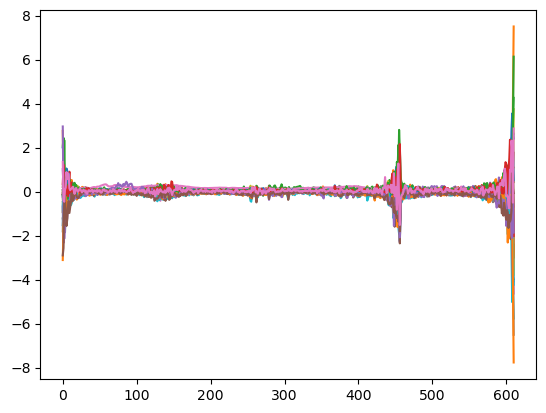

In [167]:
_ = plt.plot(background_data.T)

In [168]:
list_mode = []
for k in range(2,100):
    kmeans = KMeans(n_clusters=k, random_state=0).fit(spectra_data_bg)
    #kmeans.predict(background_data)
    list_mode.append(stats.mode(kmeans.predict(background_data)).count[0])
list_mode

[27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 27,
 14,
 27,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 11,
 11,
 14,
 11,
 8,
 8,
 12,
 8,
 8,
 9,
 8,
 7,
 8,
 6,
 6,
 6,
 7,
 5,
 5,
 6,
 4,
 6,
 6,
 5,
 5,
 4,
 4,
 5]

In [169]:
kmeans = KMeans(n_clusters=20, random_state=0).fit(spectra_data_bg)
    #kmeans.predict(background_data)
kmeans.predict(background_data)

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2], dtype=int32)

In [170]:
(kmeans1.predict(spectra_data_bg) == 2).sum()

85

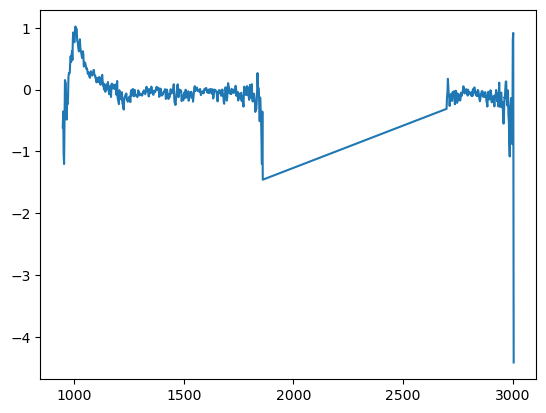

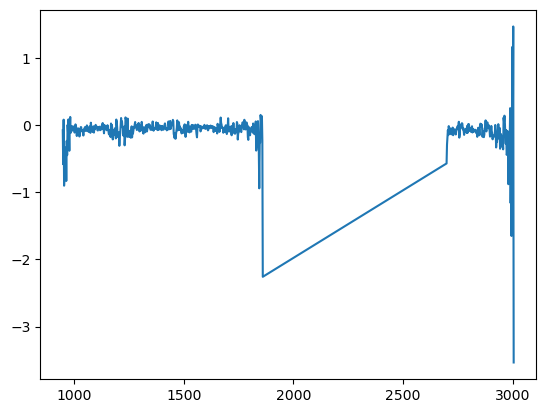

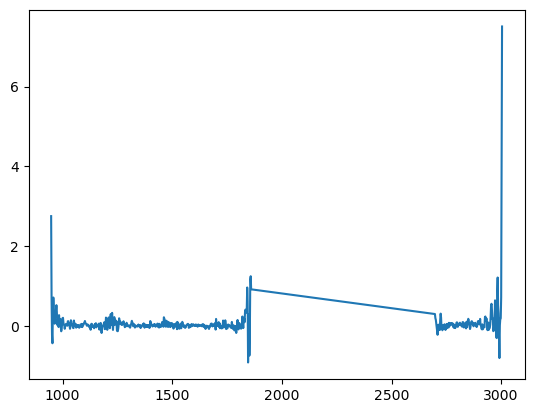

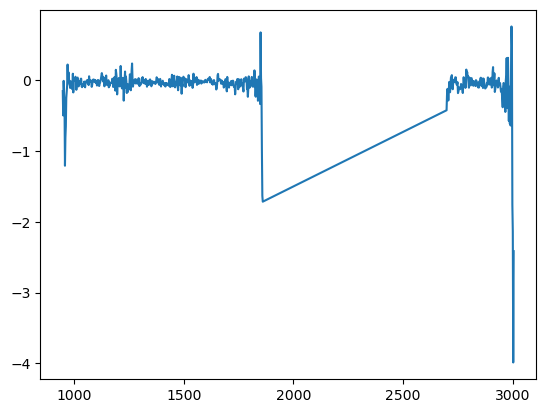

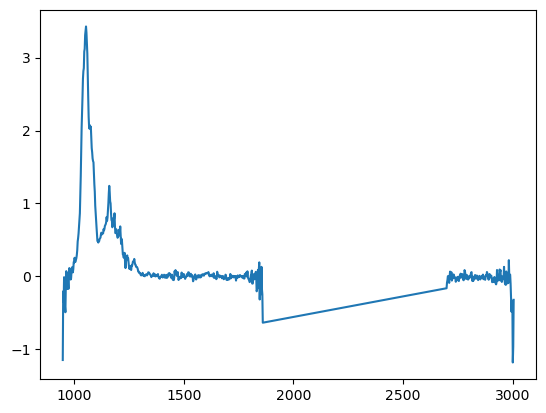

...

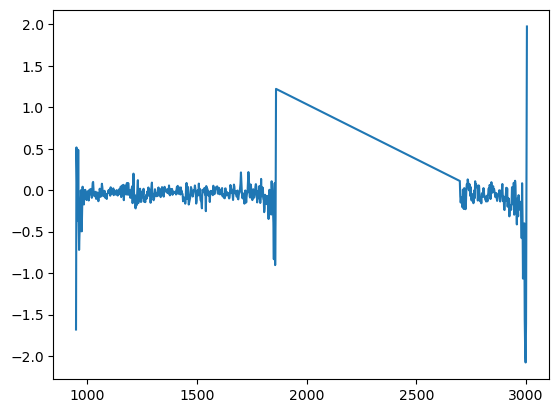

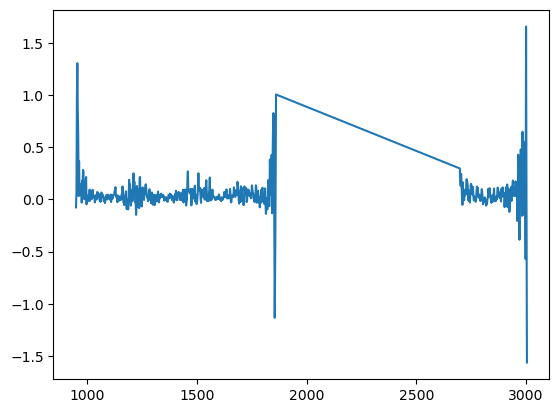

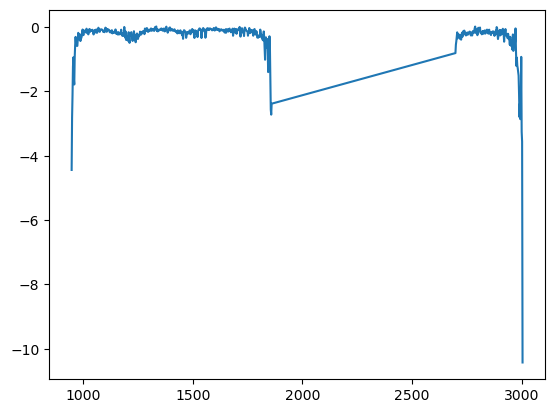

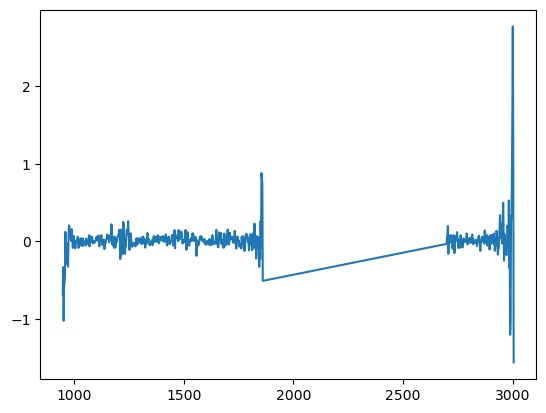

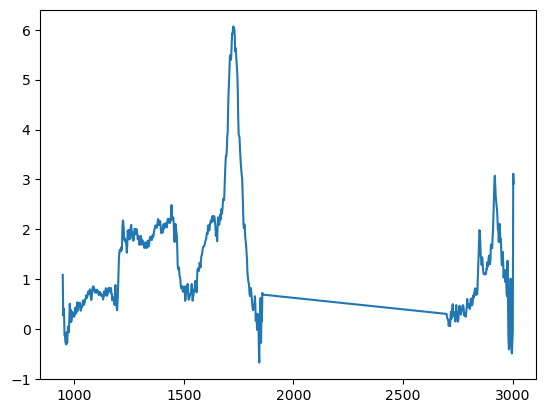

In [171]:
for i in range(83):
    s = spectra_data_bg.loc[(kmeans.predict(spectra_data_bg) == 2), :].iloc[i,:]
    plt.plot(s)
    plt.show()

In [224]:
spectra_data.shape

(155, 1029)

In [230]:
155 - 70

85

In [226]:
spectra_data_np.shape

(70, 1725)

In [172]:
spectra_data_long = spectra_data.loc[kmeans1.predict(spectra_data_bg) != 2, :].reset_index().melt(id_vars='index')
spectra_data_long.columns = ['file_name','wavelength','intensity']
spectra_data_long['polymer'] = ''
spectra_data_long_int = interpol_spect(spectra_data_long, min_wl=674.9918, max_wl=3999.809,n=1725)
spectra_data_int = spectra_data_long_int.pivot(
    index=['file_name'], 
    columns='wavelength', 
    values='intensity').reset_index()

In [173]:
spectra_data_np = np.float32(spectra_data_int.iloc[:,1:].to_numpy())

In [174]:
spectra_data_np_norm = (spectra_data_np[:,idx_range] - spectra_data_np[:,idx_range].mean(1)[:,None]) / spectra_data_np[:,idx_range].std(1)[:,None]

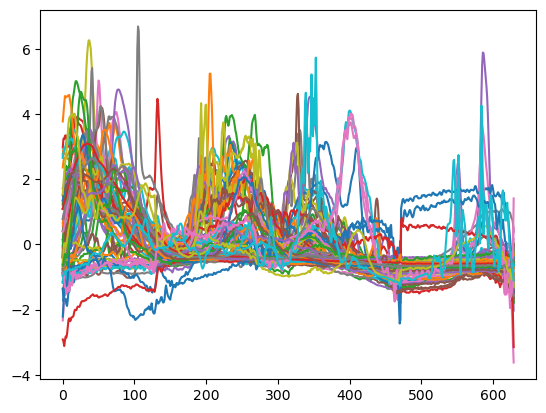

In [175]:
_ = plt.plot(spectra_data_np_norm.T)

In [176]:
clf = LogisticRegression(random_state=0, C=.1)
clf.fit(-x_train, y_train_)
clf.score(-x_test, y_test)

1.0

In [177]:
pred_prob = clf.predict_proba(spectra_data_np_norm).max(1) 
pred_poly = clf.predict(spectra_data_np_norm)

In [178]:
(pred_poly[pred_prob > .8])

array(['Polystyrene', 'Polystyrene', 'Polystyrene', 'Polystyrene',
       'Rubber', 'Polystyrene', 'Polystyrene', 'Rubber', 'Polystyrene',
       'Rubber', 'Polystyrene', 'Polystyrene', 'Polystyrene', 'Rubber',
       'Polystyrene', 'Polystyrene', 'Rubber', 'Cotton', 'Polystyrene',
       'Rubber', 'Polystyrene', 'Polystyrene', 'Rubber', 'Rubber',
       'Rubber', 'Rubber'], dtype=object)

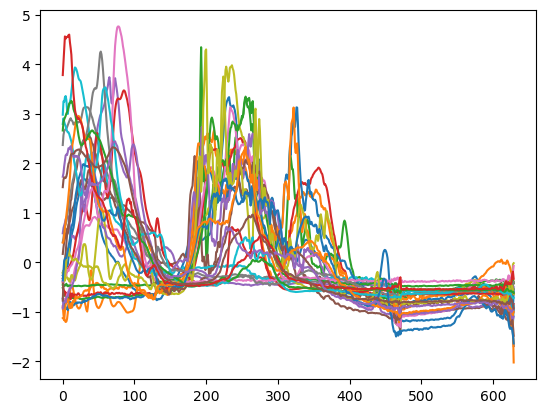

In [179]:
_ = plt.plot(spectra_data_np_norm[pred_prob > .8].T)

Polystyrene 0.9698364313556885


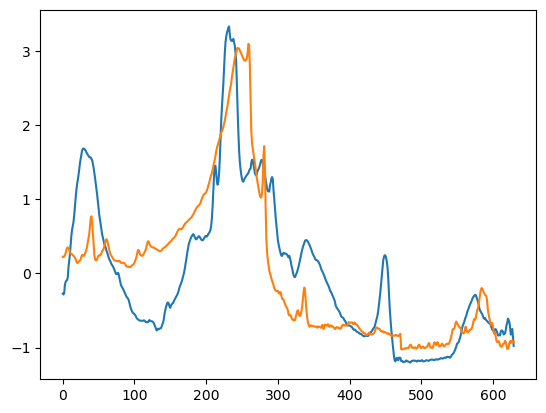

Polystyrene 0.8472084493577716


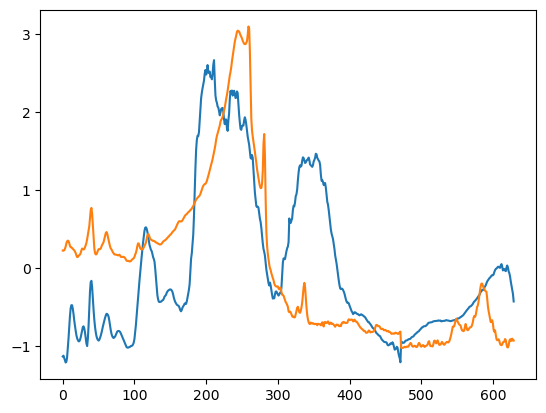

Polystyrene 0.9287589015283543


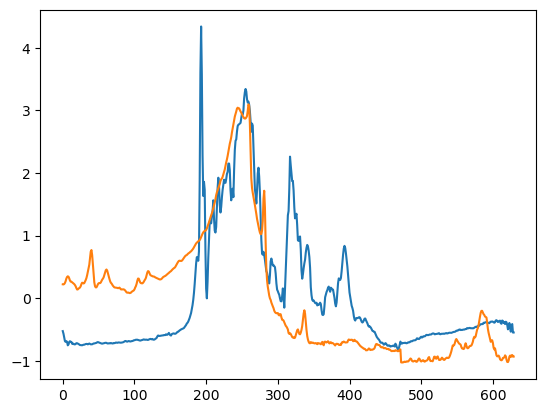

Polystyrene 0.835735752303039


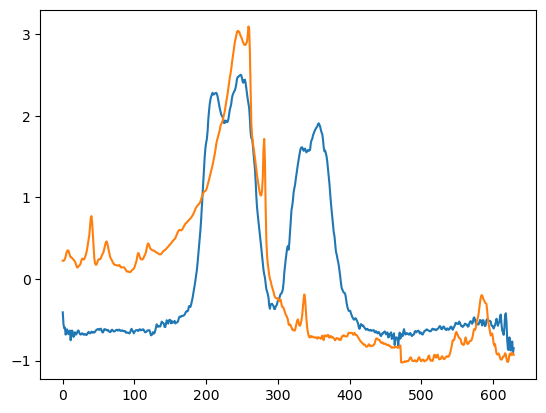

Rubber 0.8019066009447688


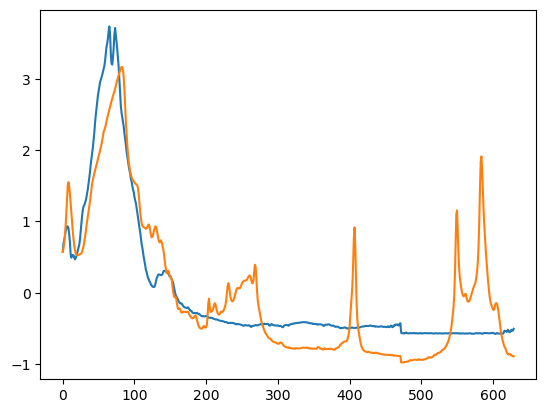

Polystyrene 0.8069739853910847


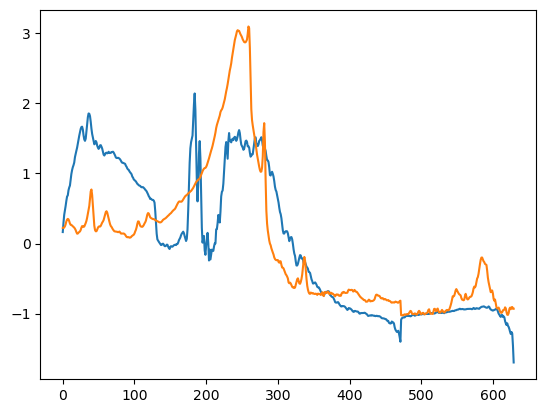

Polystyrene 0.9441897828695893


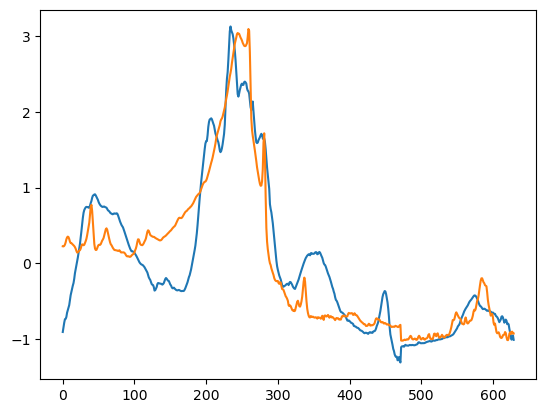

Rubber 0.9103207740155488


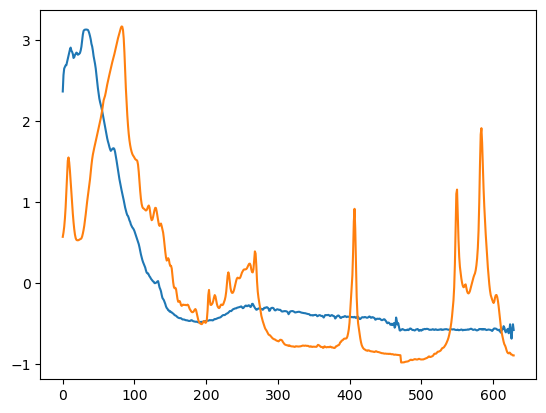

Polystyrene 0.9040843092903474


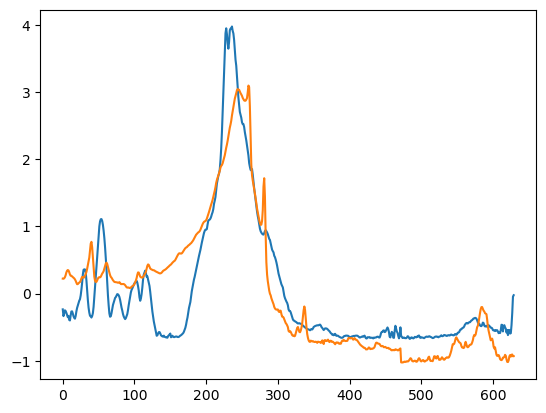

Rubber 0.809438715686166


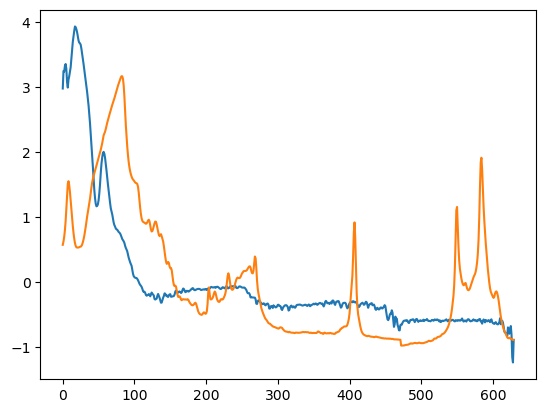

Polystyrene 0.874927780777617


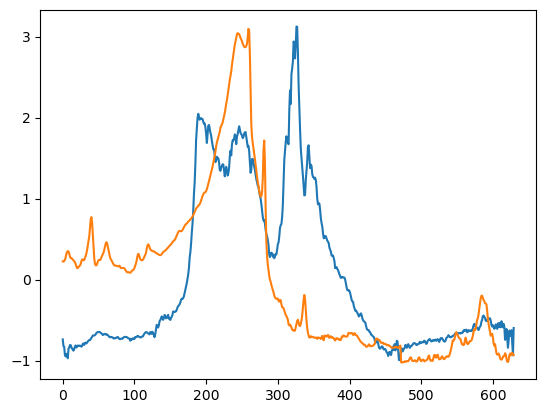

Polystyrene 0.931402146503952


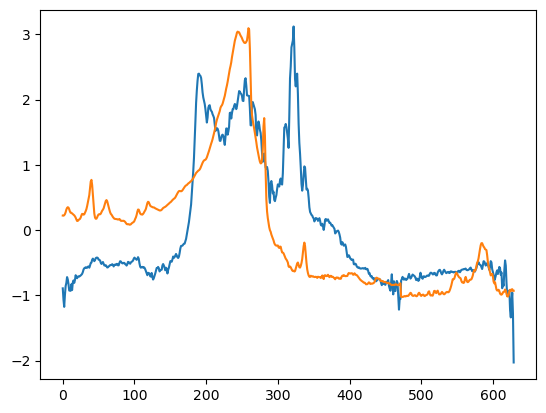

Polystyrene 0.9232310757390461


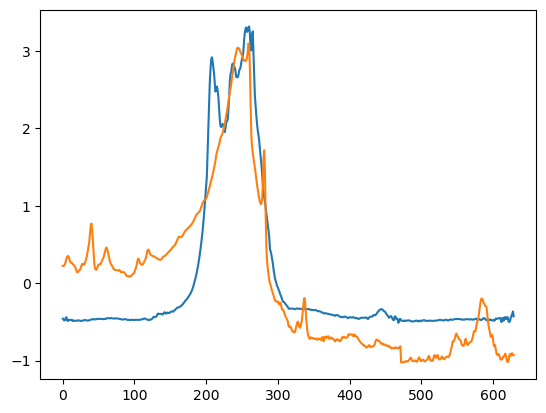

Rubber 0.8090291271922146


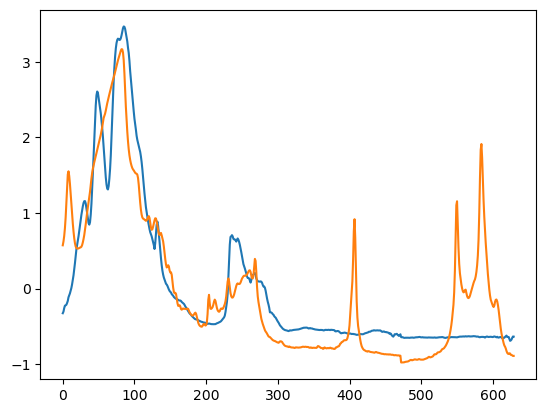

Polystyrene 0.8917865228123434


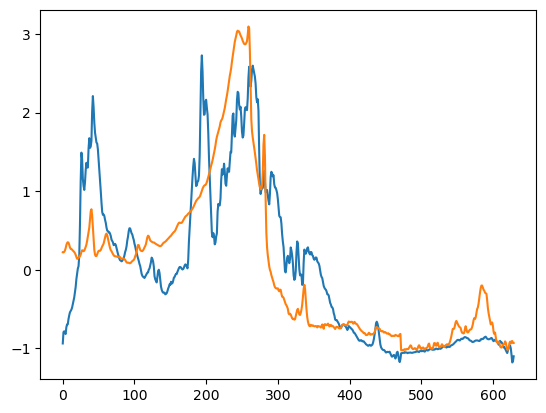

Polystyrene 0.9336166803133799


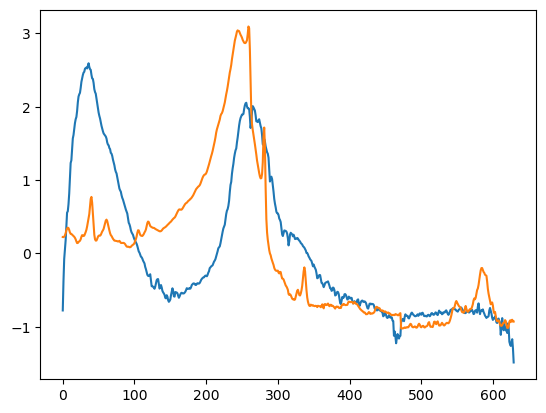

Rubber 0.9648334148934123


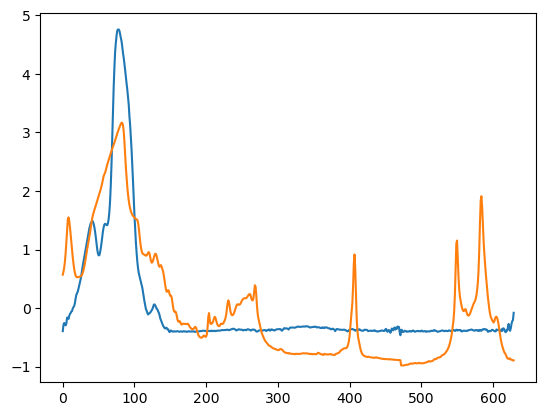

Cotton 0.9003477905507163


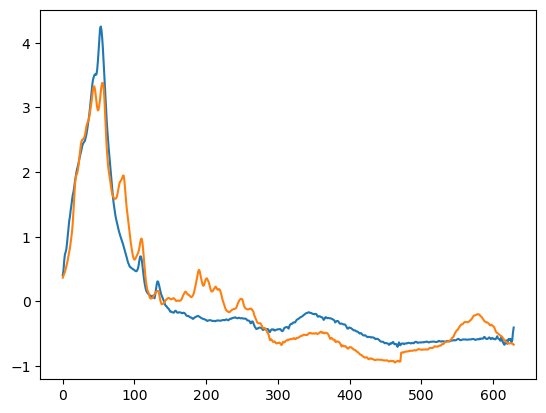

Polystyrene 0.9228092025671294


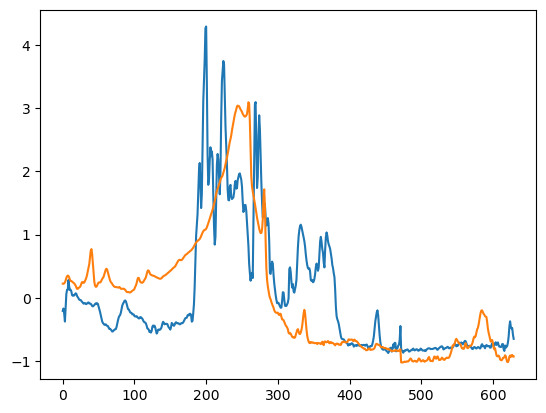

Rubber 0.9163359284490494


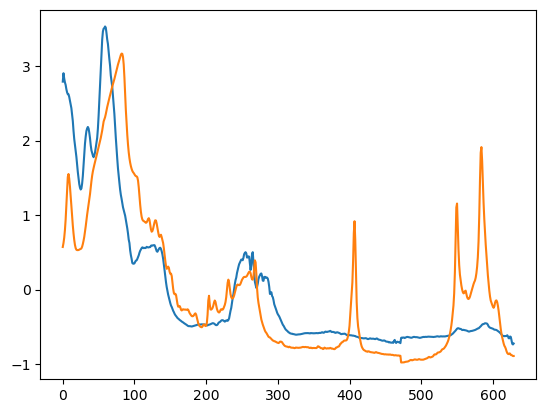

Polystyrene 0.9351083488217087


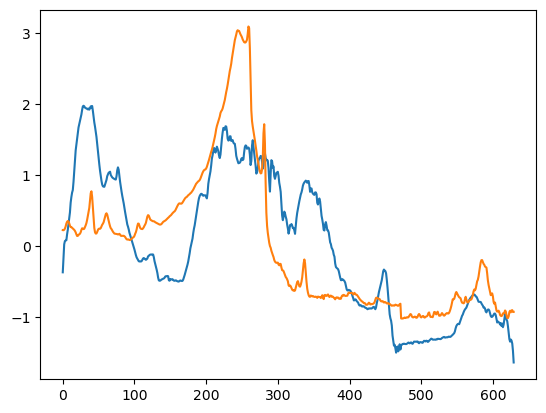

Polystyrene 0.9260670431761625


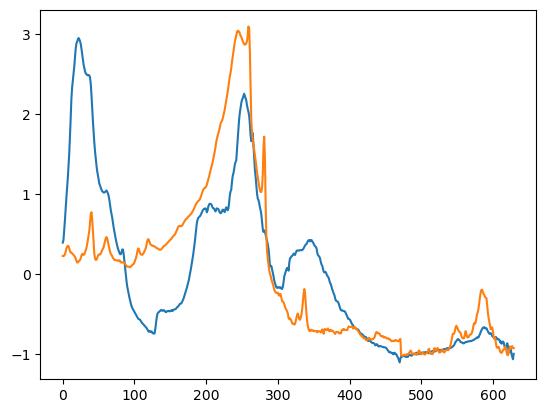

Rubber 0.8725215391537839


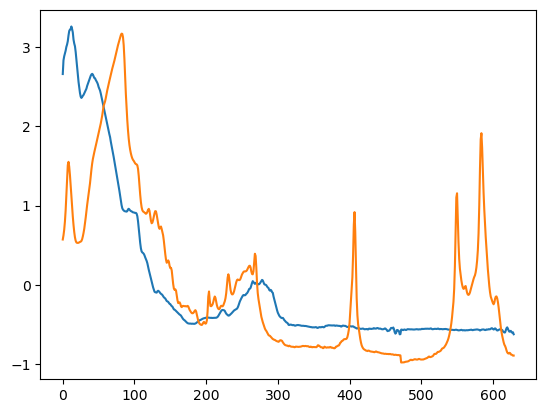

Rubber 0.9835095555821104


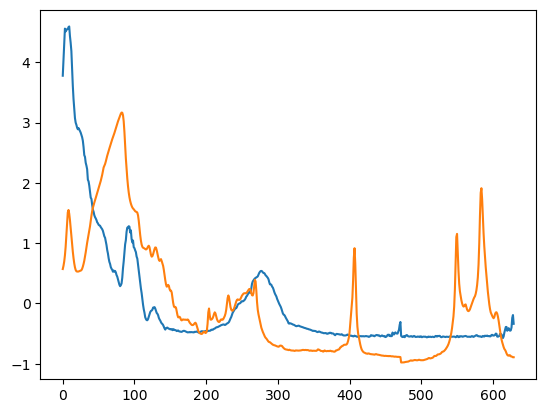

Rubber 0.8775395877291517


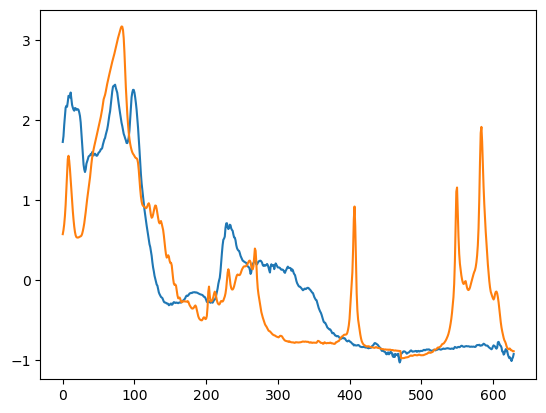

Rubber 0.8615993853071784


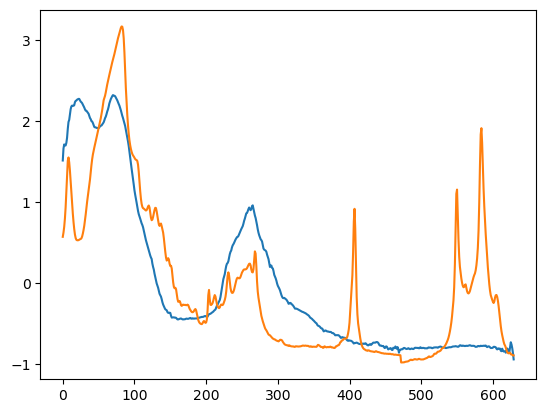

In [180]:
for i, s in enumerate(spectra_data_np_norm):
    if pred_prob[i] < .8:
        continue
    print(pred_poly[i], pred_prob[i])
    plt.plot(s)
    plt.plot(-x_train[y_train_ == pred_poly[i]][0])
    #plt.plot(-X_train.loc[y_train_ == pred_poly[i],:].iloc[0,:].to_numpy())
    
    plt.show()

Cotton 0.636460054550356


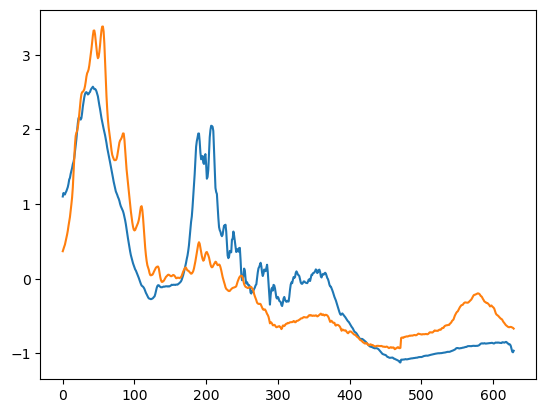

Rubber 0.47126489202621136


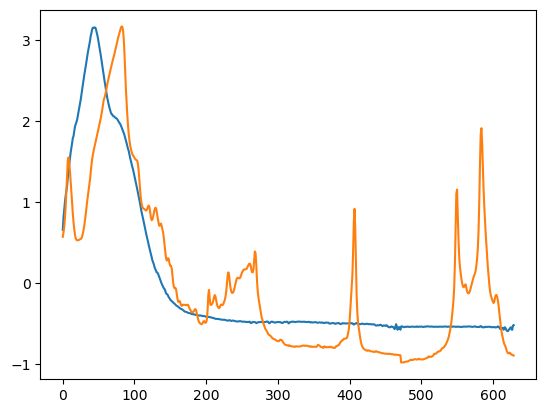

Polystyrene 0.7128651103711425


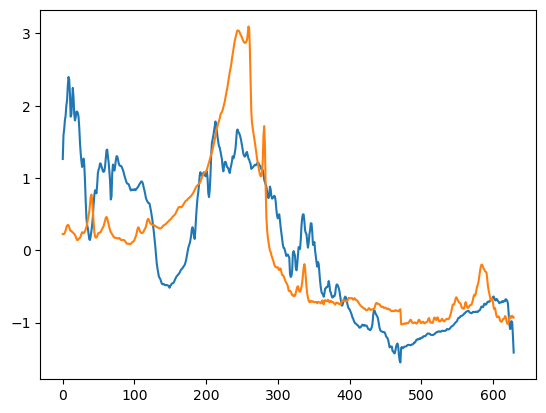

Rubber 0.428539403534684


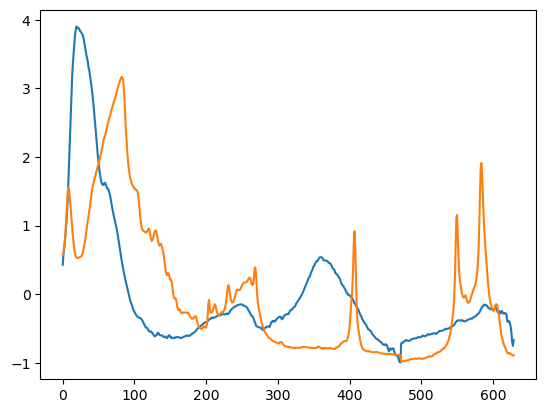

Cotton 0.6188739058316354


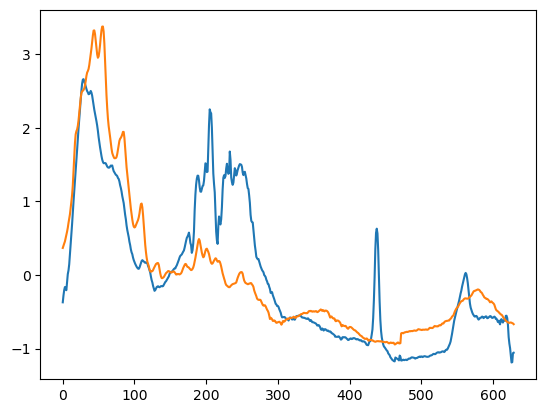

Polyethylene 0.3910918349472201


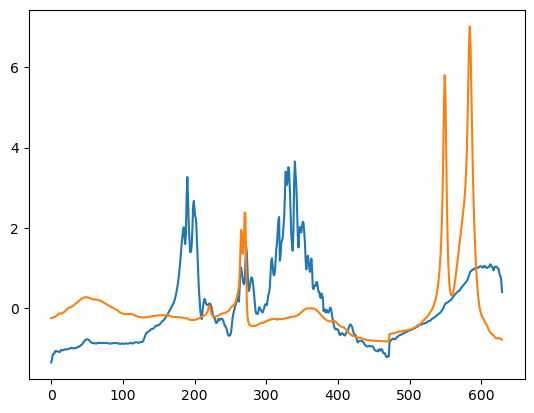

Polystyrene 0.7683085540322274


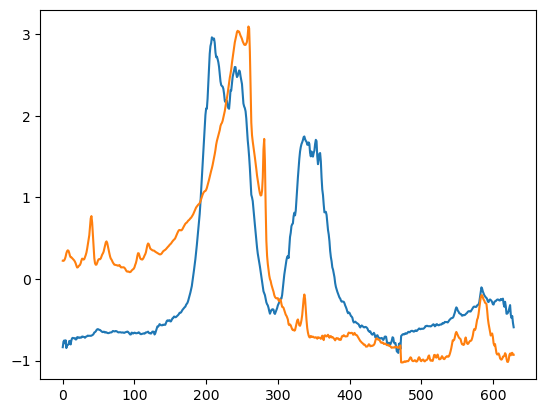

Rubber 0.3090839272325028


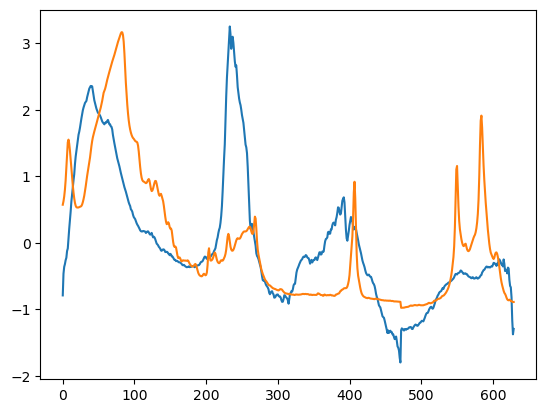

Polystyrene 0.6108109376764366


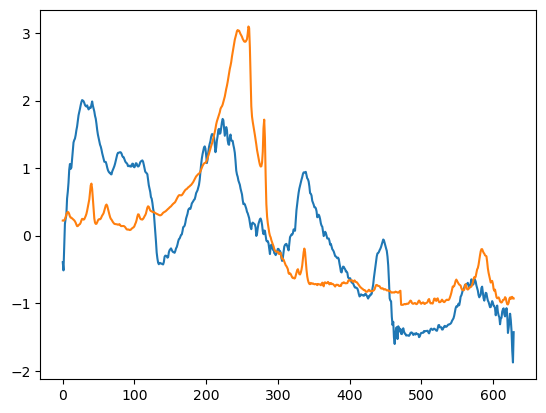

Polyethylene Vinyl Acetate 0.2896431259601244


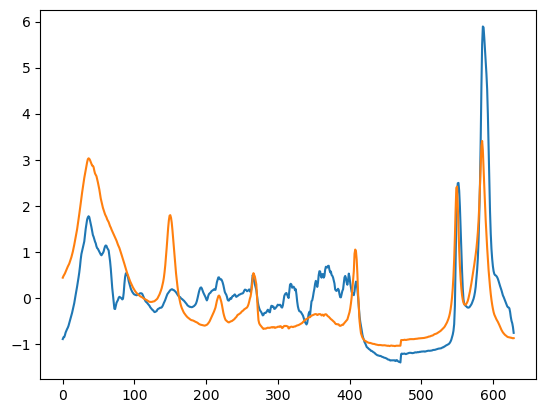

Polystyrene 0.36530365469688986


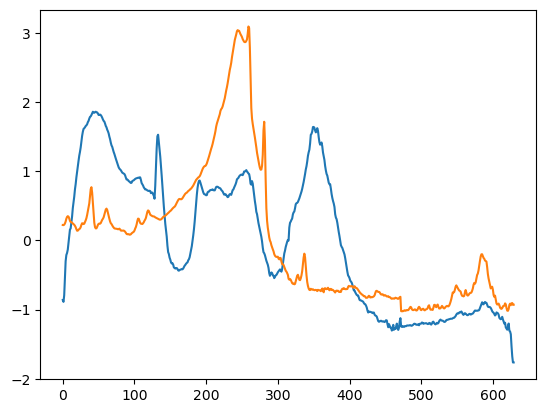

Rubber 0.7209413642246


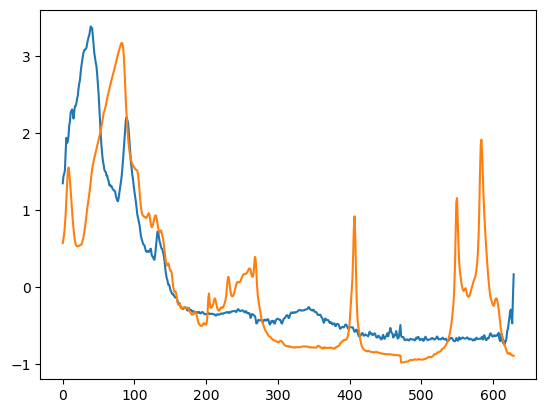

Cotton 0.6940283606729054


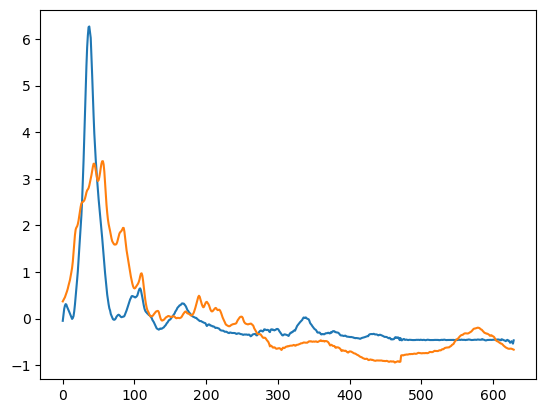

Polyethylene 0.3014014551934621


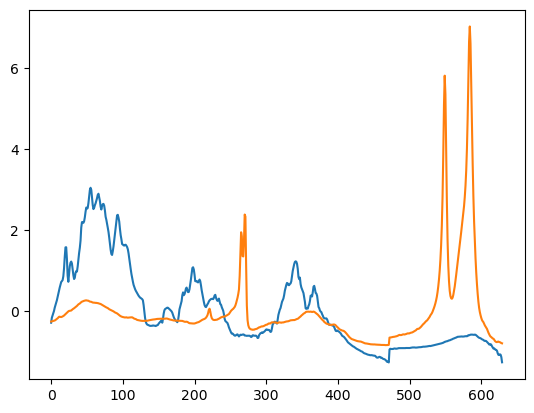

Rubber 0.42407838382797813


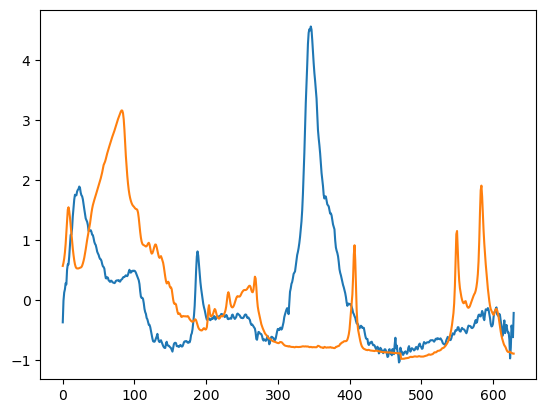

Polystyrene 0.6060596495814813


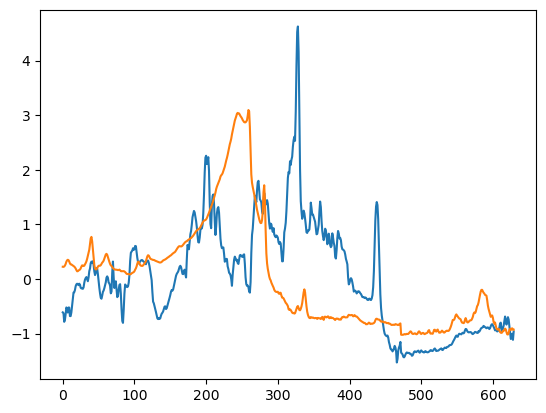

Rubber 0.39254639132465824


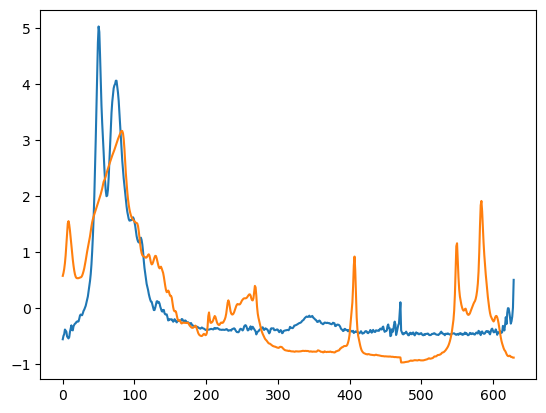

Rubber 0.3801921659679666


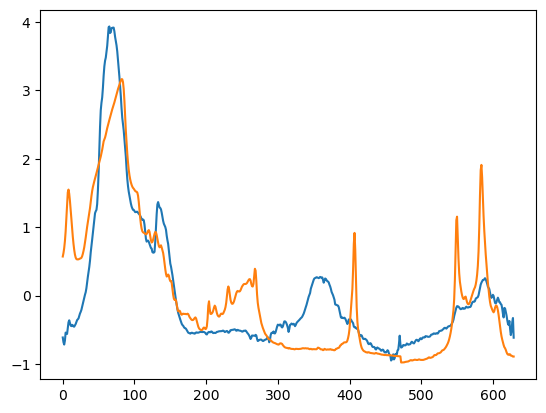

Rubber 0.7934554107825816


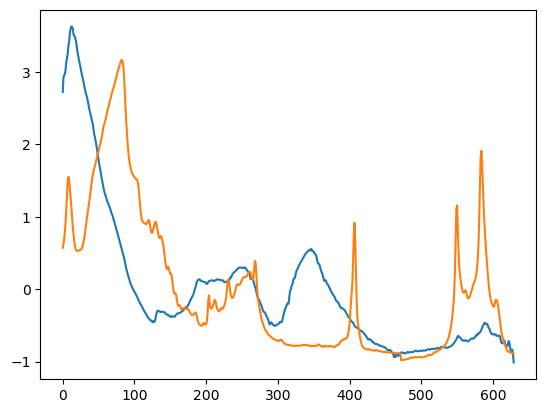

Polyamide 0.5988863098938698


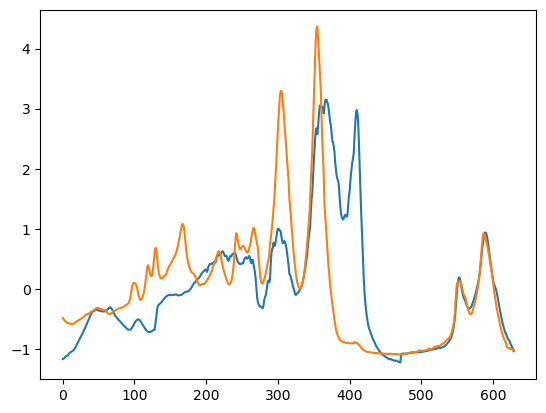

Polystyrene 0.7828871701900393


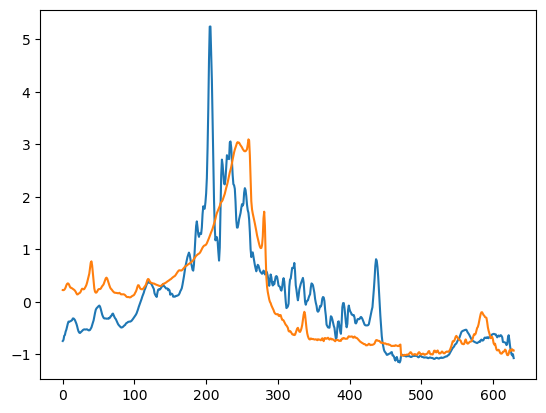

Rubber 0.371428985035603


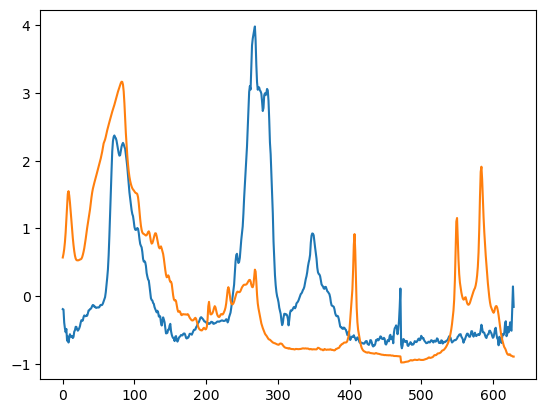

Rubber 0.7049271483657881


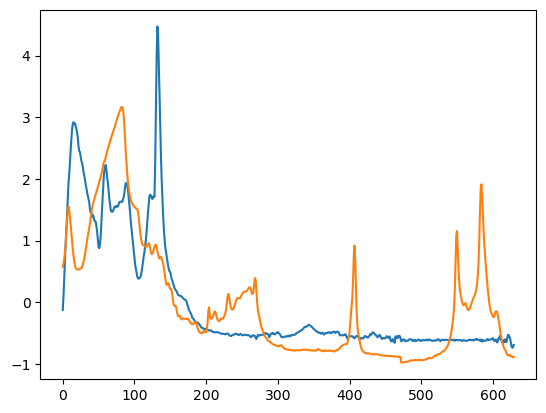

Rubber 0.5785554098679095


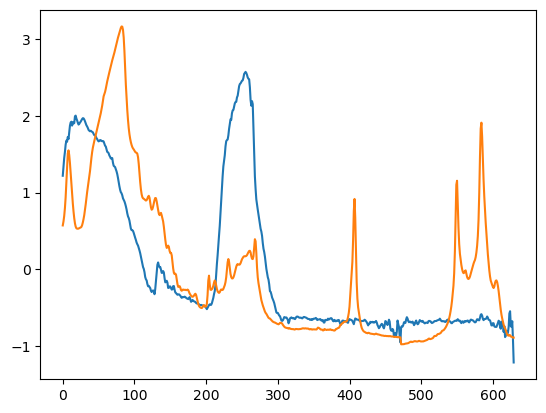

Ethylene Acrylic Acid 0.26469863756999346


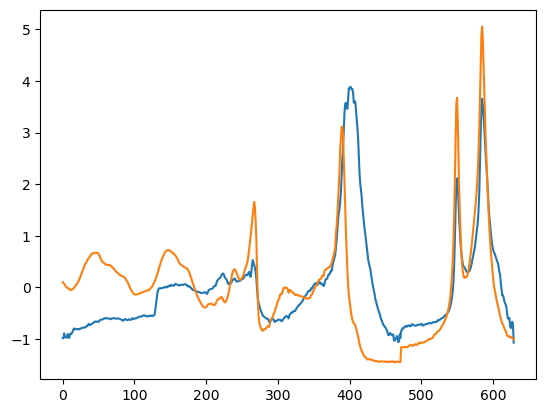

Cotton 0.3236153011490659


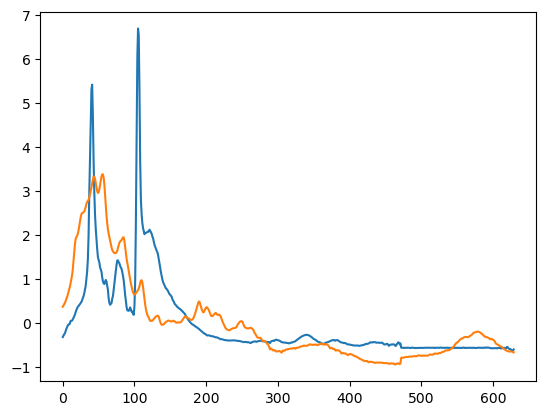

Rubber 0.5374109535420646


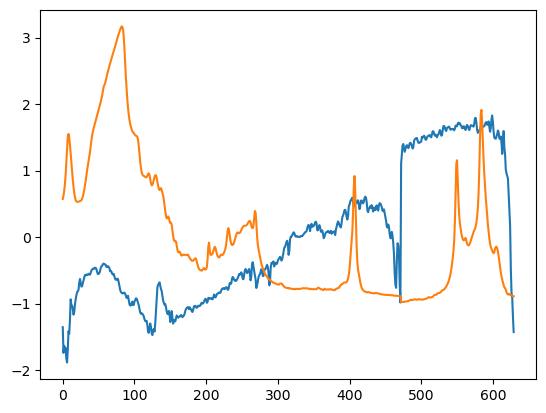

Rubber 0.7671205245396002


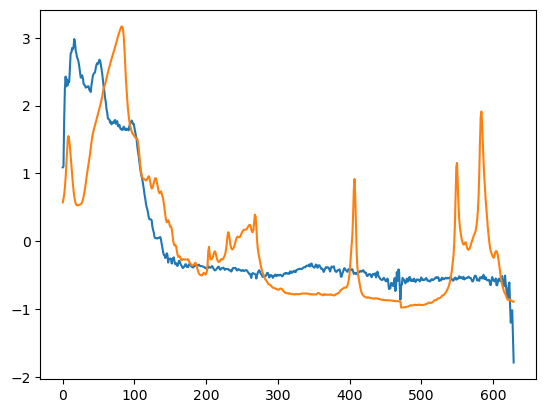

Cotton 0.6989619154651661


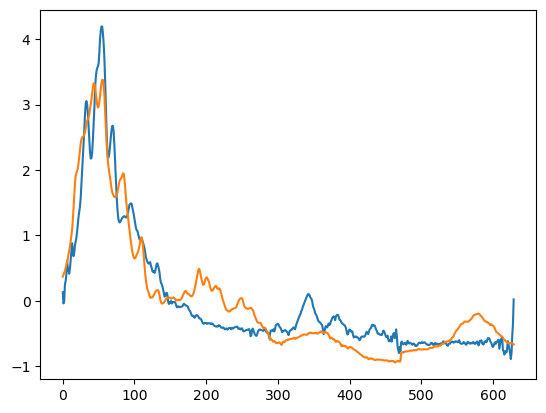

Polyethylene Terephthalate 0.36431837228142594


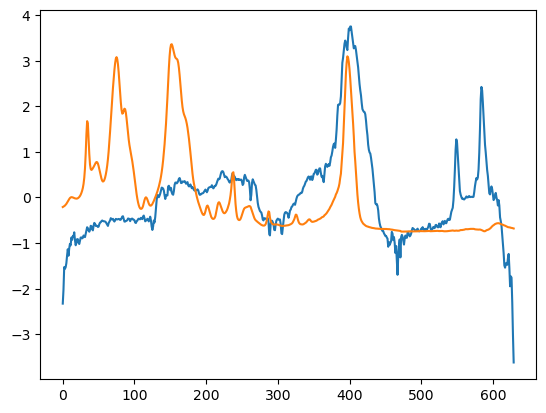

Polyethylene Terephthalate 0.35894652374130265


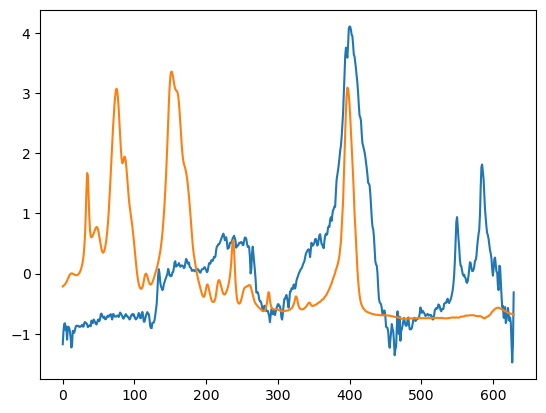

Polypropylene 0.5275290661697786


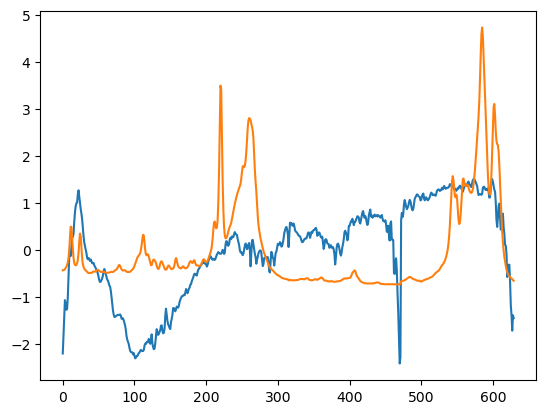

Cotton 0.5627000186066408


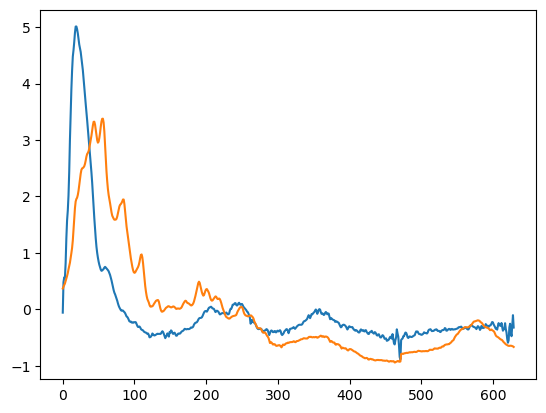

Polystyrene 0.552672786948023


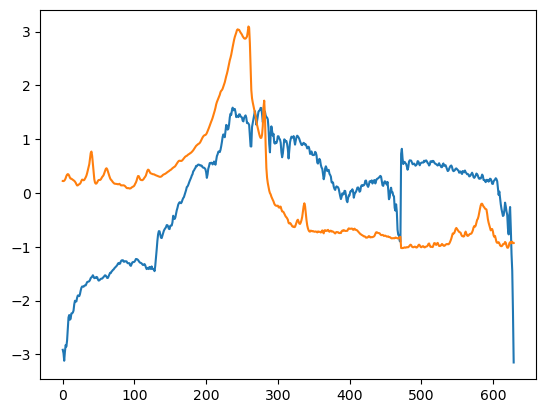

Rubber 0.6321788029061145


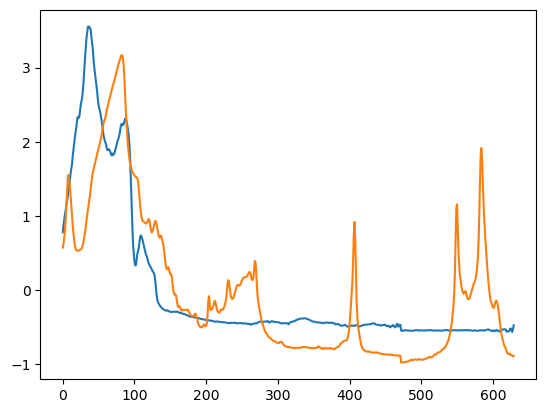

Polystyrene 0.7228305865298026


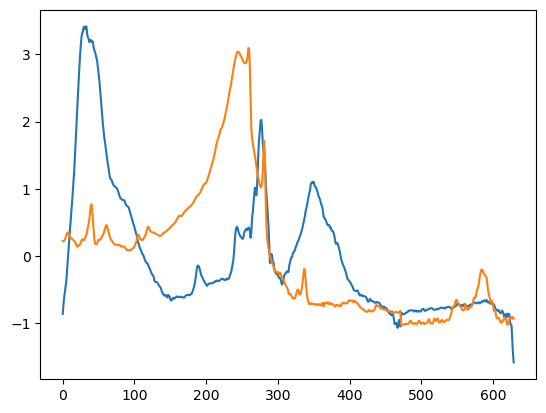

Cotton 0.37045422341473583


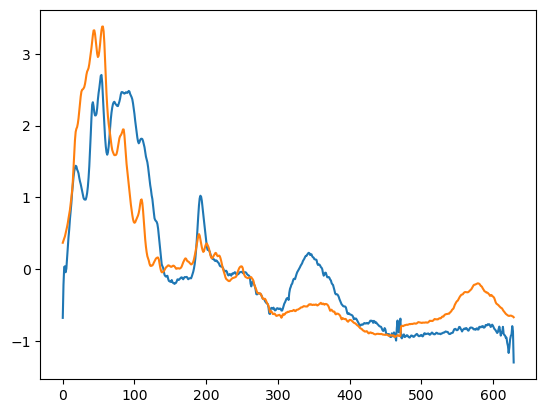

Rubber 0.5714001790672181


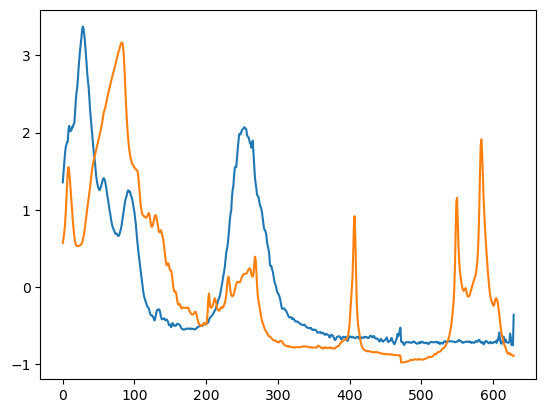

Polystyrene 0.5235099090840043


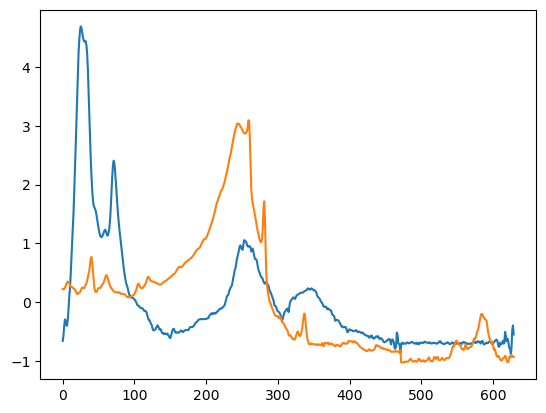

Rubber 0.5163637176578726


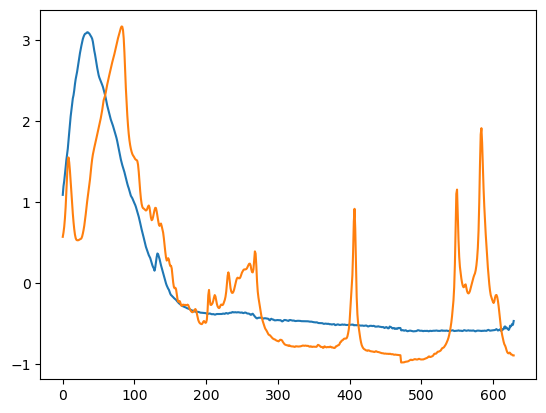

Polyethylene Terephthalate 0.4958633821634382


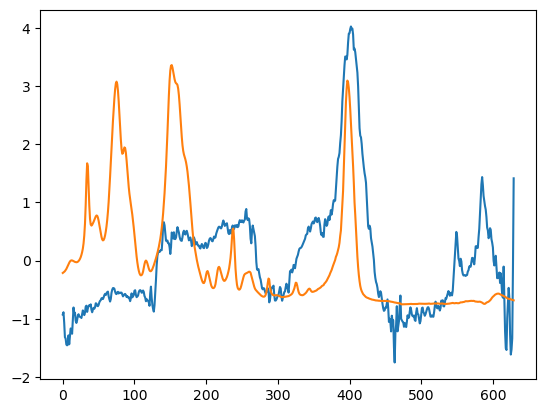

Rubber 0.7836872152944004


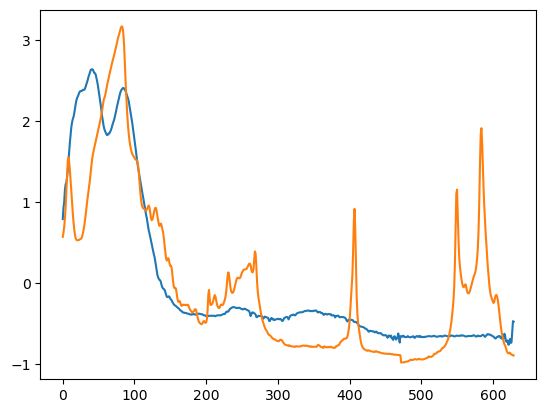

Rubber 0.7379680581214363


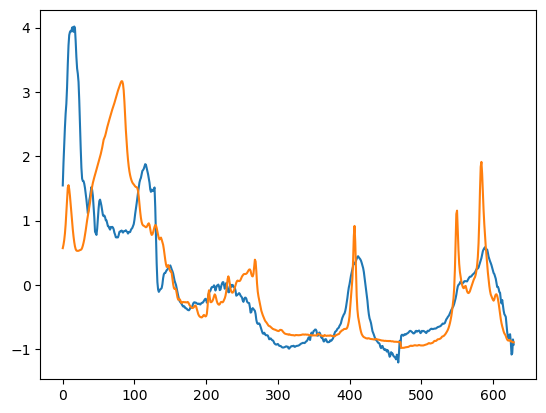

Polyethylene 0.399420938168832


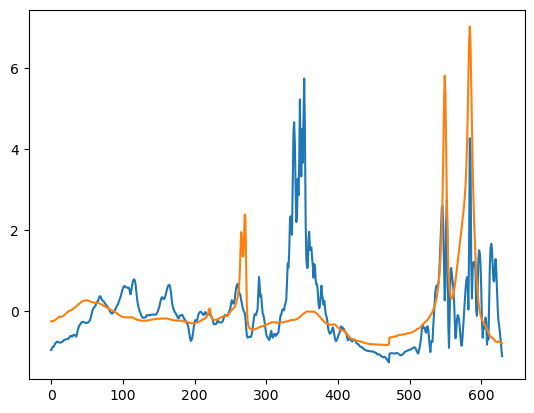

In [181]:
for i, s in enumerate(spectra_data_np_norm):
    if pred_prob[i] >= .8:
        continue
    print(pred_poly[i], pred_prob[i])
    plt.plot(s)
    plt.plot(-x_train[y_train_ == pred_poly[i]][0])
    #plt.plot(-X_train.loc[y_train_ == pred_poly[i],:].iloc[0,:].to_numpy())
    
    plt.show()

In [182]:
pred_polymers_hqi = corr_matching(-x_train, y_train, spectra_data_np_norm, r_min=0.7)[0].to_numpy()
pred_hqi = corr_matching(-x_train, y_train, spectra_data_np_norm, r_min=0.7)[1]#.to_numpy()
#pred_probs_hqi = np.round(corr_matching(-x_train, y_train, spectra_df_long_int_pivot.iloc[:,1:].iloc[:,idx_range], r_min=0.7)[1]*100)


In [183]:
(pred_polymers_hqi[pred_probs_hqi > .8])

array(['Polystyrene', 'Rubber', 'Polystyrene', 'Polypropylene',
       'Polystyrene', 'Rubber', 'Cotton', 'Polystyrene', 'Polystyrene',
       'Cotton', 'Polyurethane', 'Rubber', 'Polyethylene', 'Polystyrene',
       'Cotton', 'Polystyrene', 'Polystyrene', 'Rubber', 'Rubber',
       'Polystyrene', 'Cotton', 'Polystyrene', 'Rubber', 'Polystyrene',
       'Cotton', 'Polystyrene', 'Rubber', 'Cotton', 'Cotton', 'Rubber',
       'Rubber', 'Rubber', 'Polystyrene', 'Polystyrene', 'Rubber',
       'Polyethylene', 'Polystyrene', 'Polystyrene', 'Polystyrene',
       'Cotton', 'Polystyrene', 'Polystyrene', 'Rubber'], dtype=object)

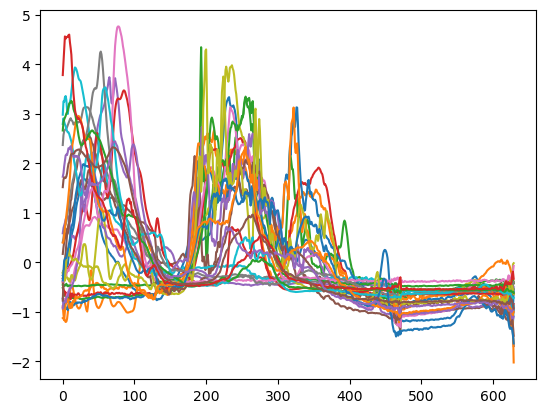

In [184]:
_ = plt.plot(spectra_data_np_norm[pred_prob > .8].T)

0 Polystyrene 0.8868920284767547


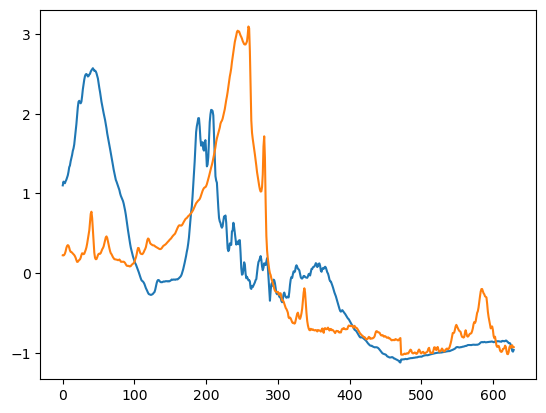

1 Rubber 0.9628951474436862


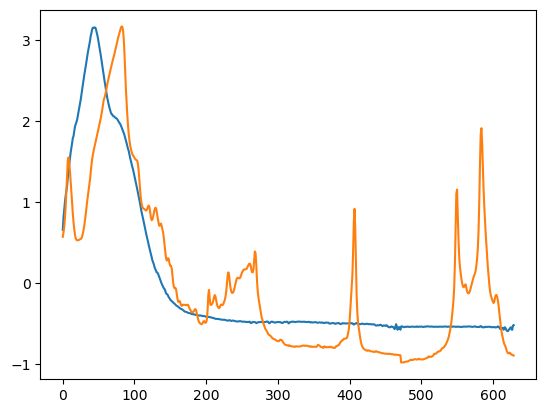

2 Polystyrene 0.8449769470583496


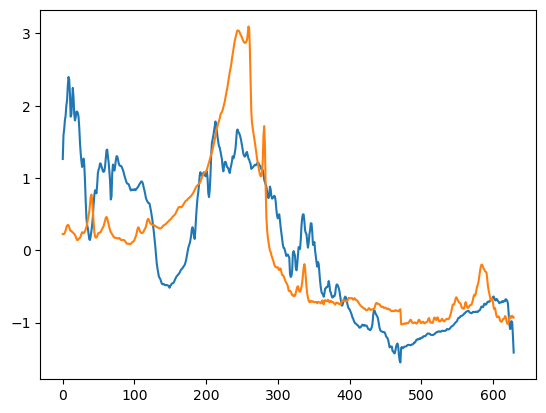

3 Polypropylene 0.8703251486038867


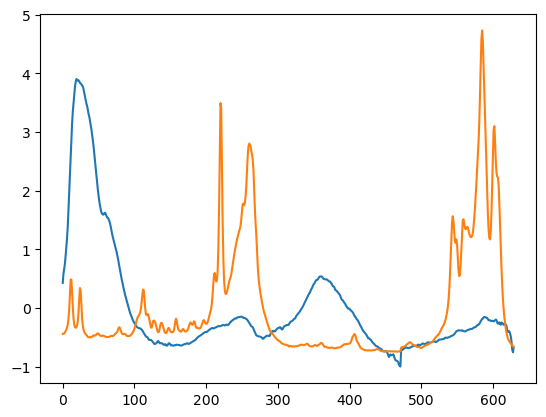

6 Polystyrene 0.8688734560216684


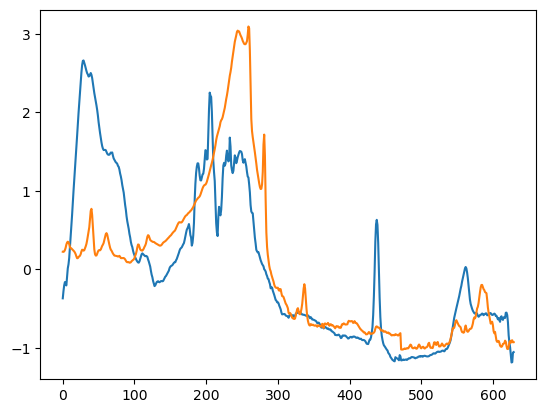

11 Rubber 0.9716444431652107


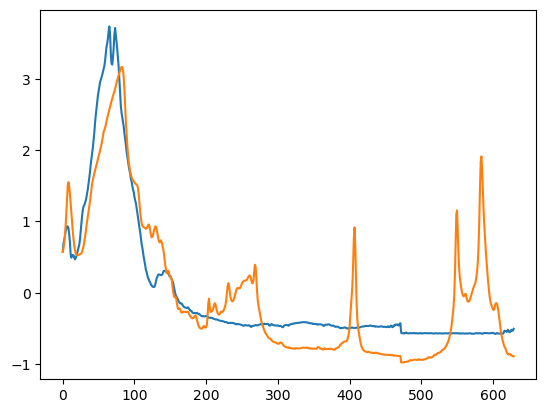

12 Cotton 0.8546961745220775


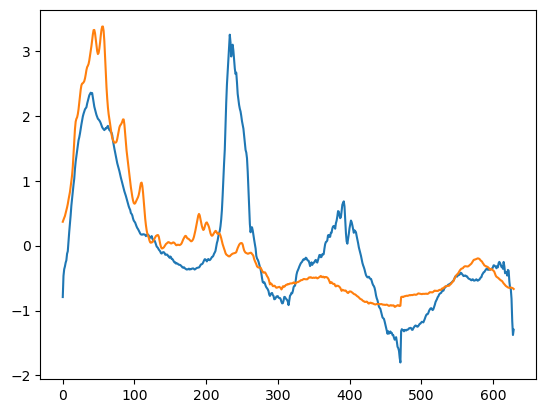

13 Polystyrene 0.8860301521994987


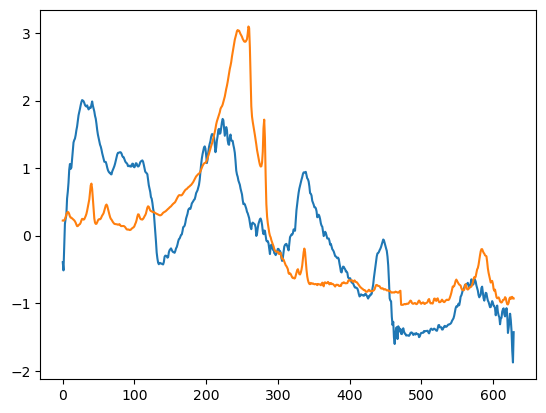

15 Polystyrene 0.8890393440102502


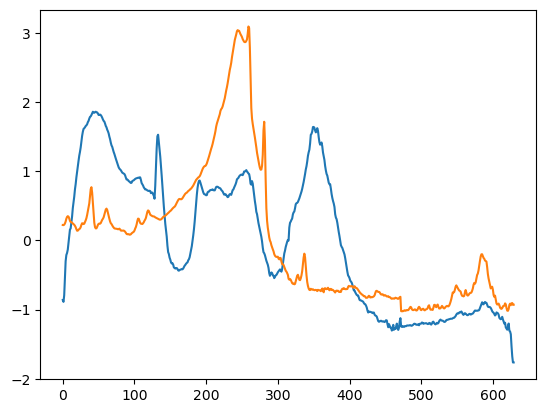

16 Cotton 0.9344628907463857


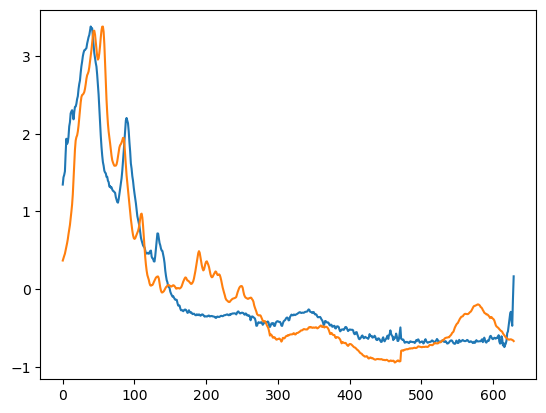

17 Polyurethane 0.8366279151601981


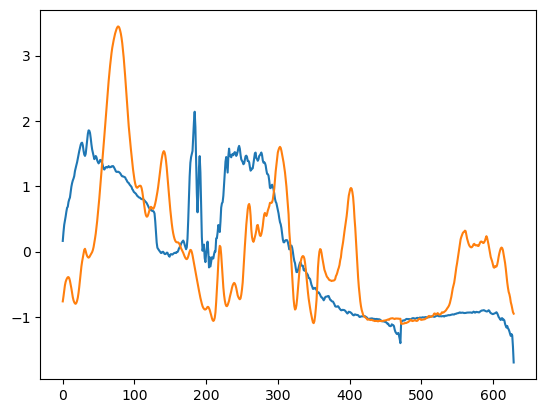

18 Rubber 0.8697781617796688


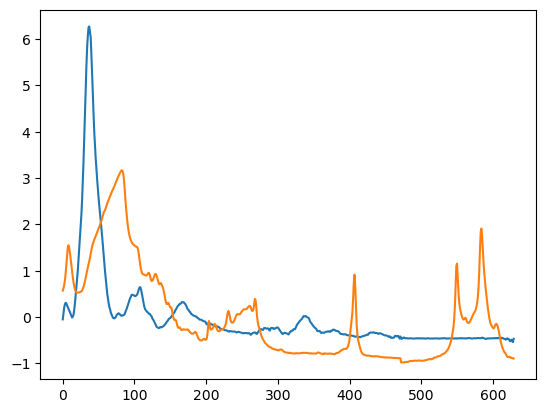

19 Polyethylene 0.9002923342218361


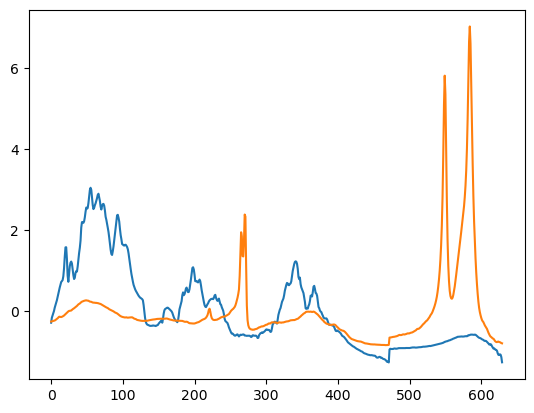

20 Polystyrene 0.9001080475792209


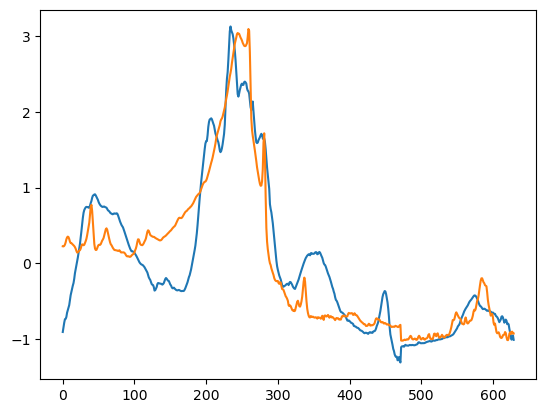

21 Cotton 0.9243243482992782


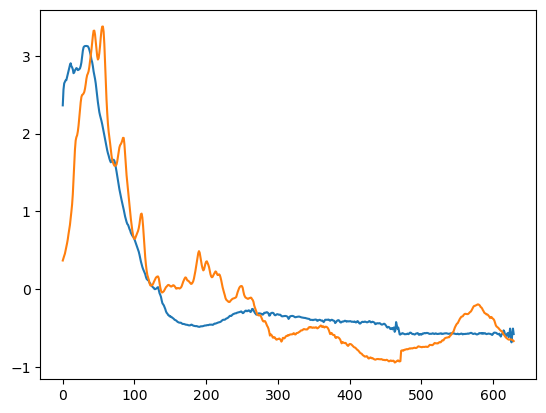

22 Polystyrene 0.8703828885376693


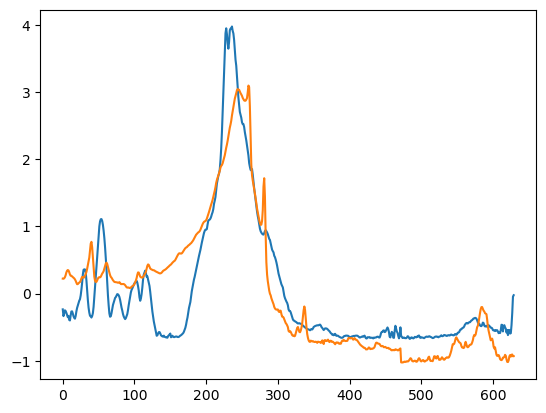

23 Polystyrene 0.8642955186769912


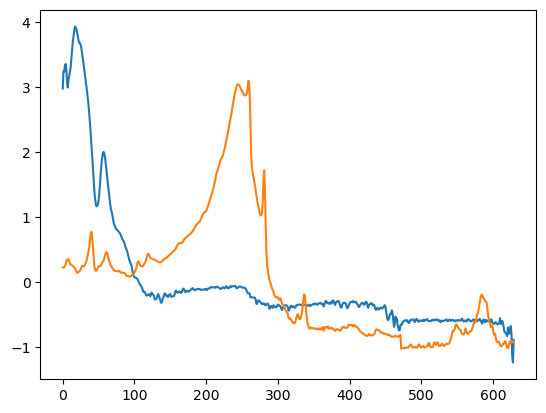

26 Rubber 0.8886712726363938


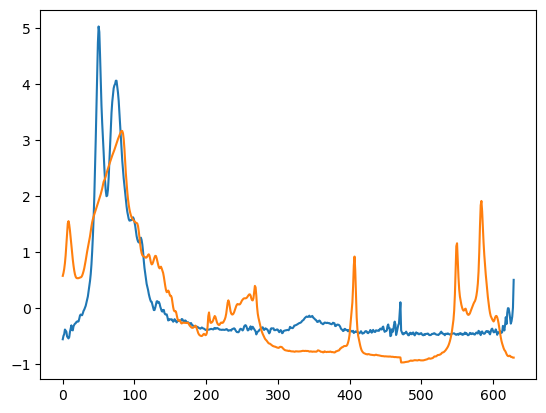

27 Rubber 0.9274432809635719


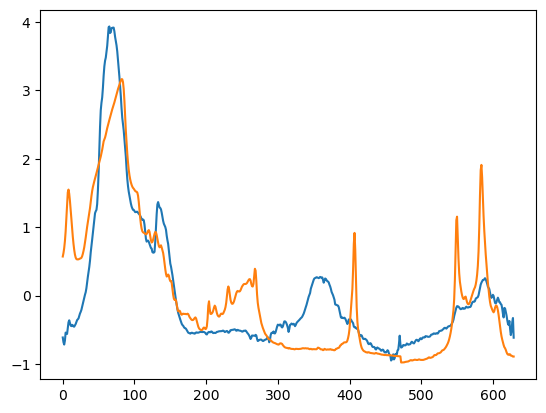

29 Polystyrene 0.8917831121045178


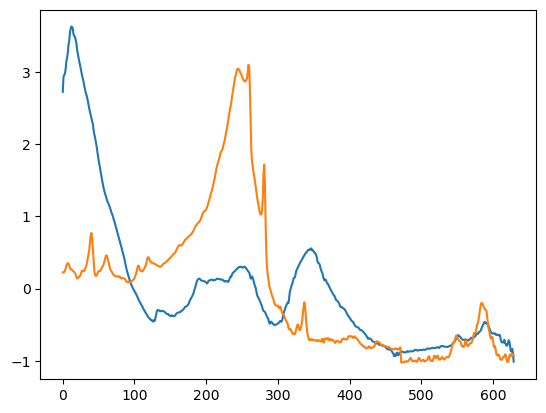

35 Cotton 0.8535295141535025


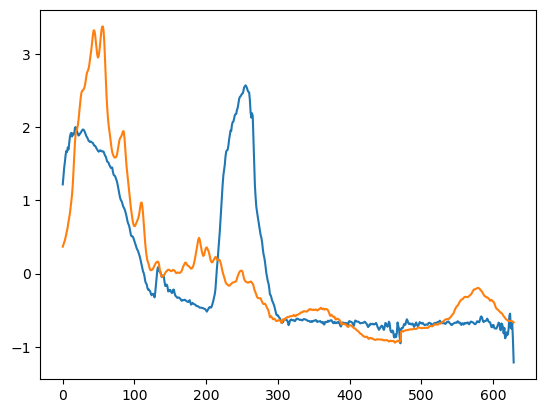

38 Polystyrene 0.8410368860039809


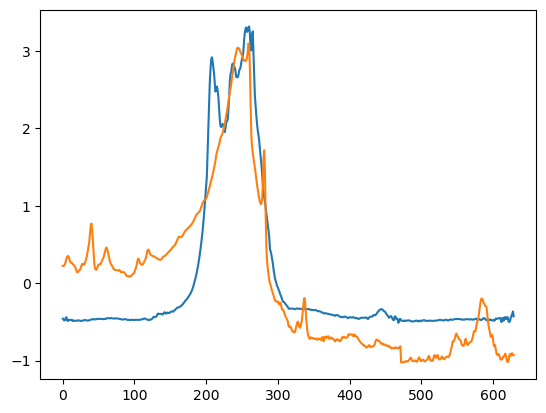

39 Rubber 0.9100196300479945


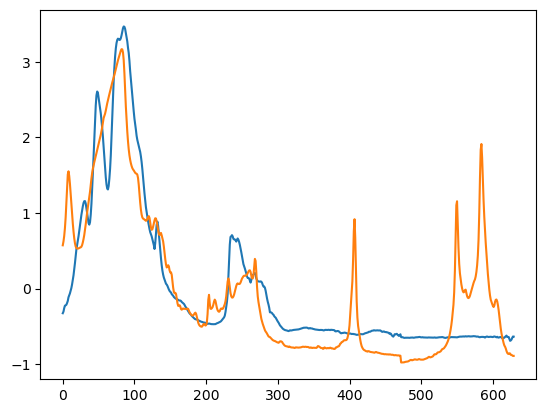

41 Polystyrene 0.8254887069428962


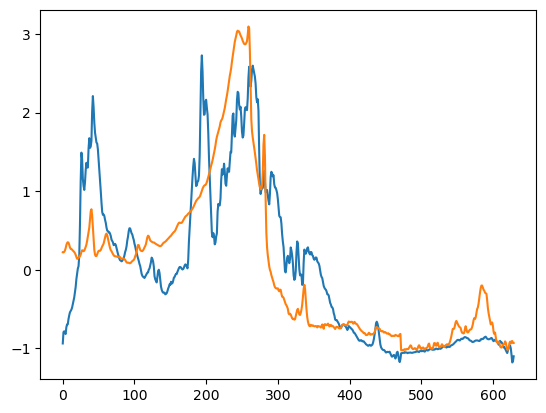

42 Cotton 0.9198485036370188


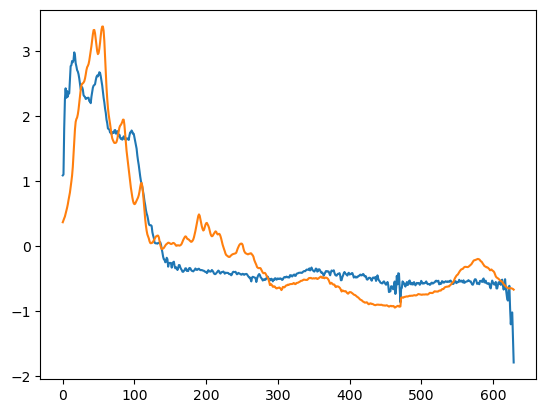

43 Polystyrene 0.8274049618221109


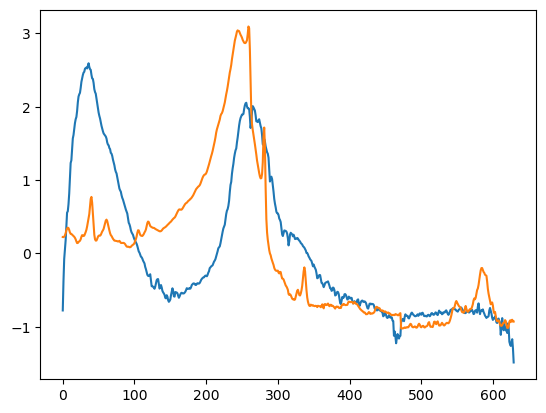

44 Rubber 0.8729512176965746


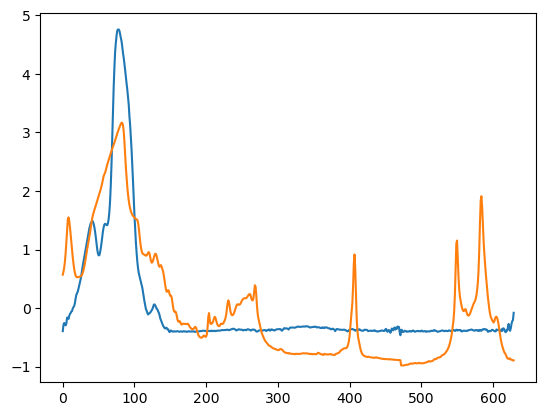

45 Cotton 0.9409873829512287


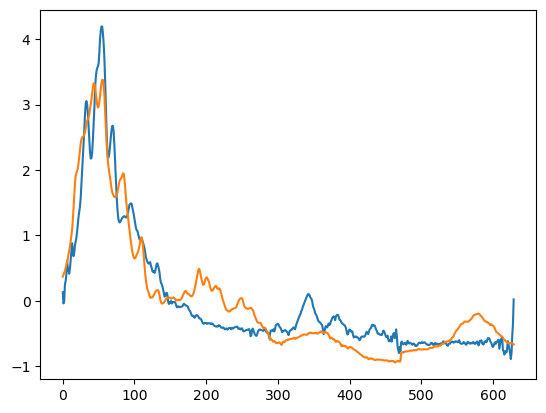

47 Cotton 0.9703088392578386


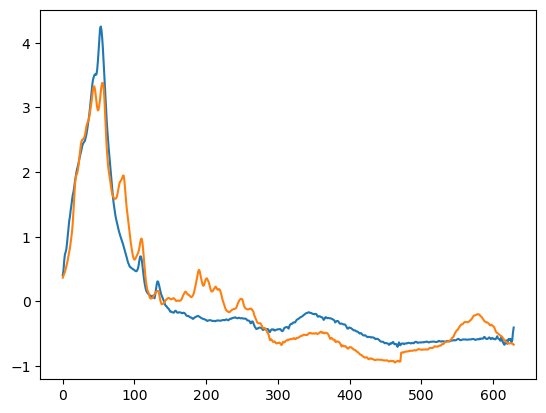

51 Rubber 0.8972955335855427


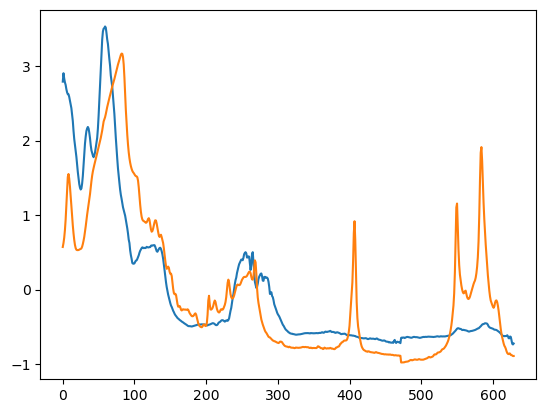

52 Rubber 0.8032138401586122


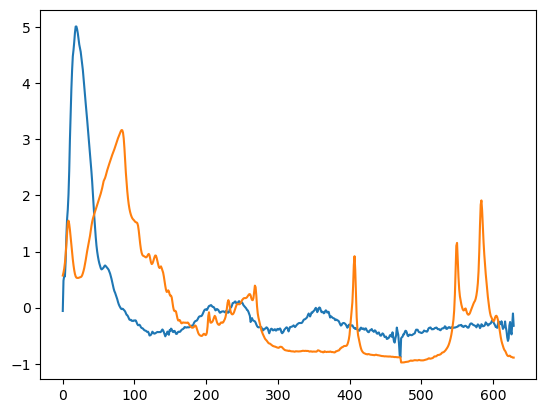

54 Rubber 0.9524049254157414


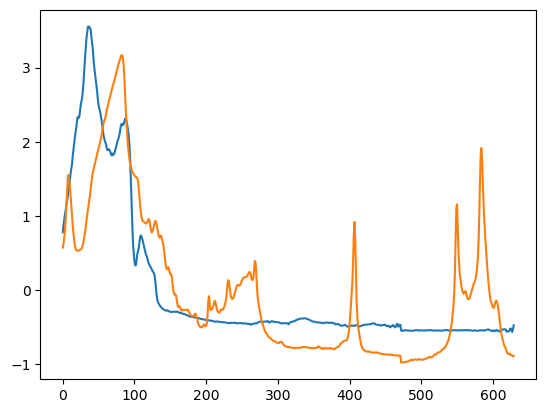

55 Polystyrene 0.8812401619439627


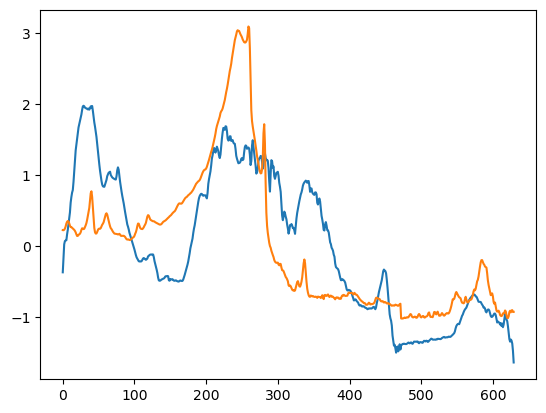

56 Polystyrene 0.8390042401873853


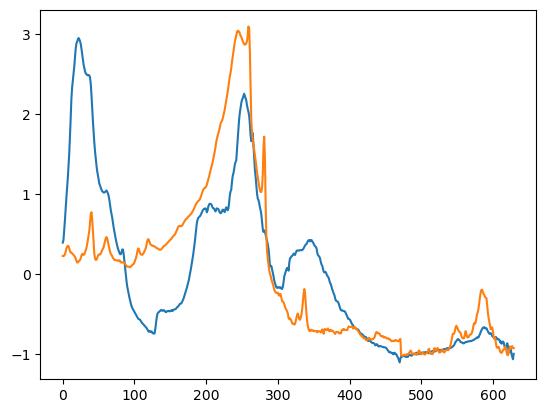

57 Rubber 0.8689126606885448


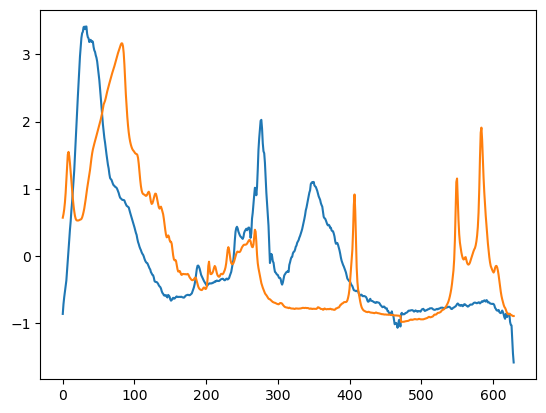

58 Polyethylene 0.8909708447714955


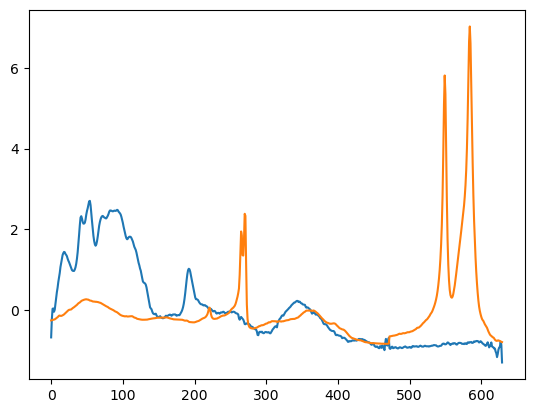

59 Polystyrene 0.9145553693299397


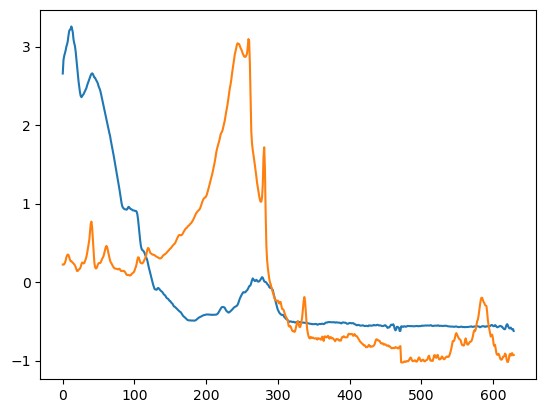

60 Polystyrene 0.8594145833655693


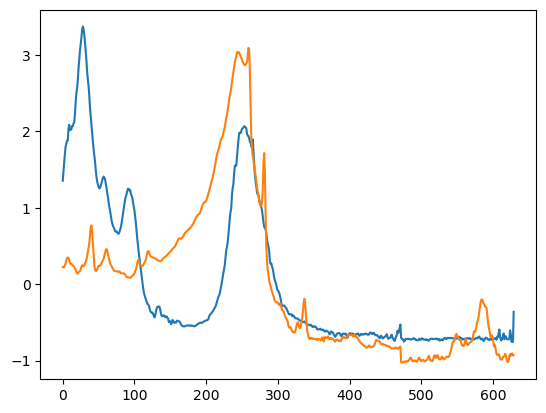

62 Polystyrene 0.8501936642555482


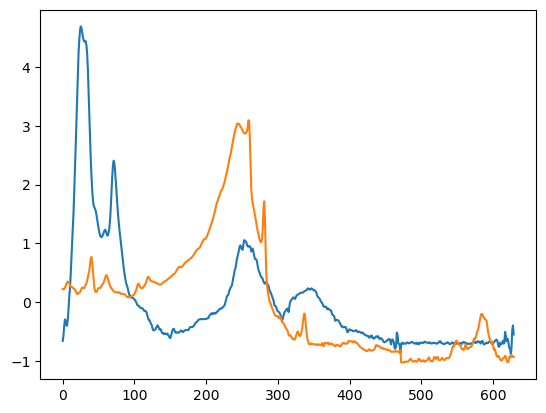

63 Cotton 0.964641338257267


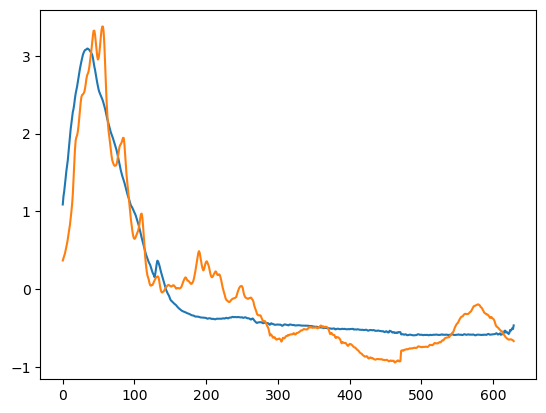

64 Polystyrene 0.8956921483060865


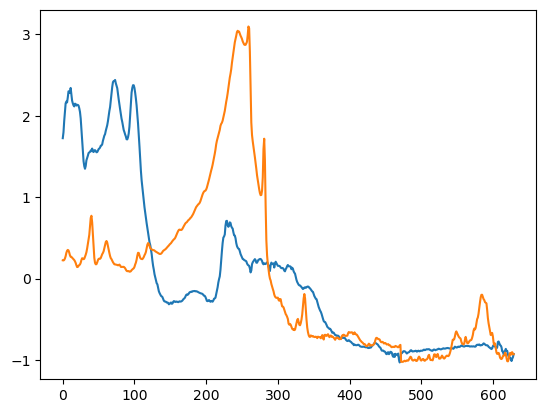

65 Polystyrene 0.9396100191206452


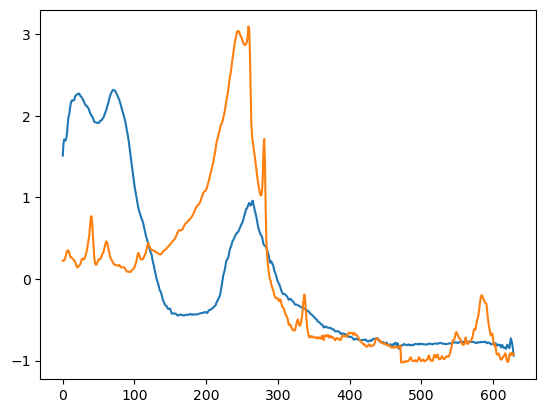

67 Rubber 0.9308942096011746


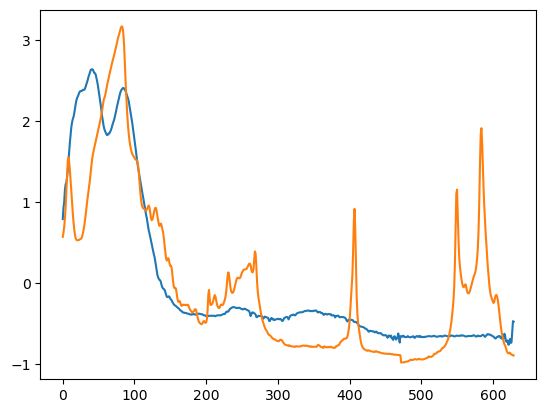

In [185]:
for i, s in enumerate(spectra_data_np_norm):
    if pred_hqi[i] < .8:
        continue
    print(i, pred_polymers_hqi[i], pred_hqi[i])
    plt.plot(s)
    plt.plot(-x_train[y_train_ == pred_polymers_hqi[i]][0])
    #plt.plot(-X_train.loc[y_train_ == pred_poly[i],:].iloc[0,:].to_numpy())
    
    plt.show()

Polystyrene 0.7944395021949818


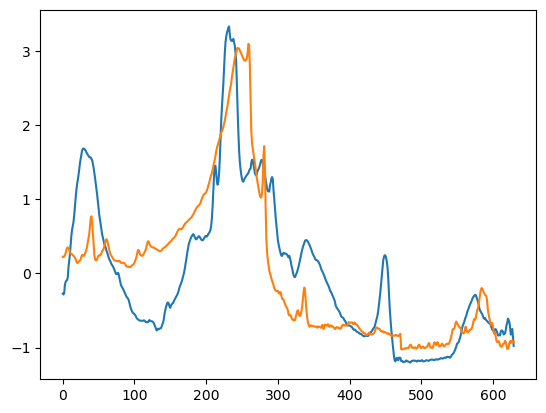

Polystyrene 0.6889868753429403


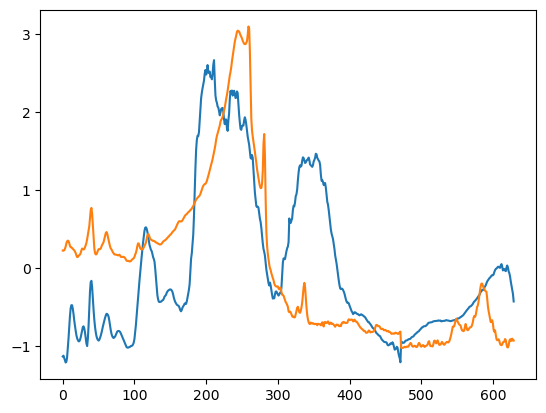

Polyamide 0.5315445055459185


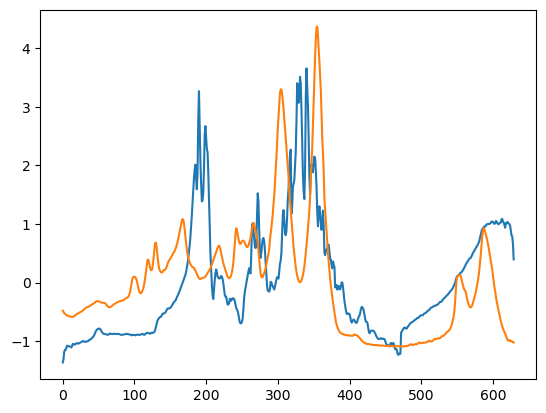

Polystyrene 0.6746221129643324


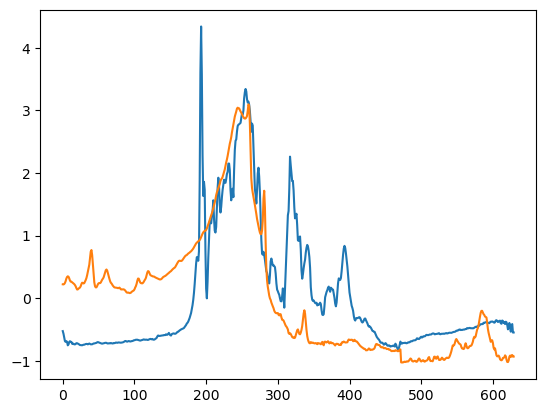

Polystyrene 0.6470184929152951


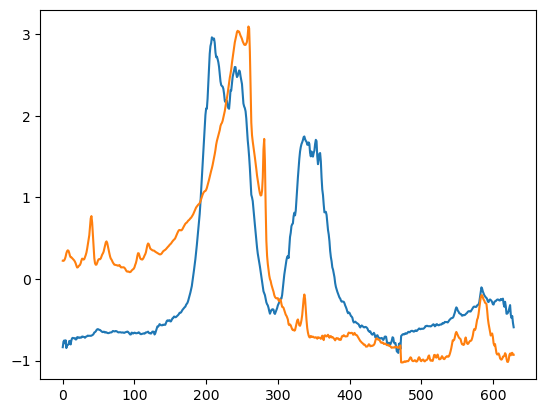

Polystyrene 0.6739156893780751


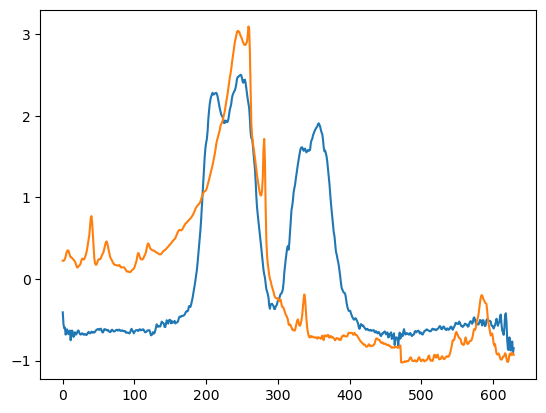

Ethylene Acrylic Acid 0.7856653559670888


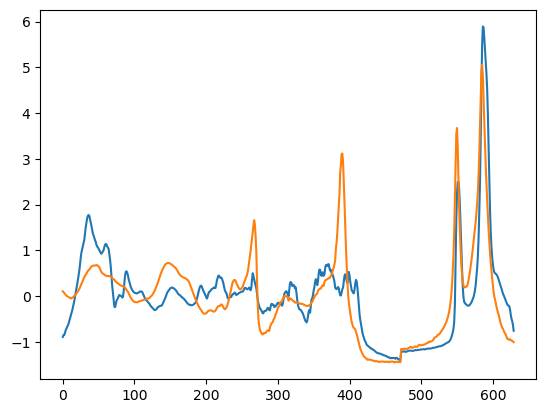

Rubber 0.7508074934498526


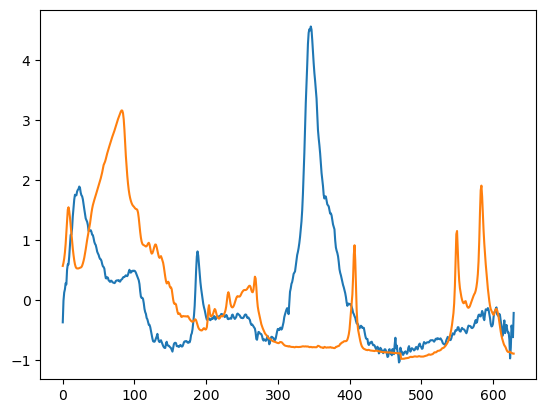

Polystyrene 0.6654653793150292


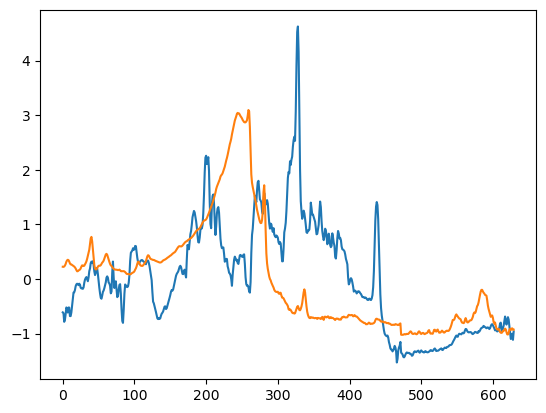

Polystyrene 0.648869560606954


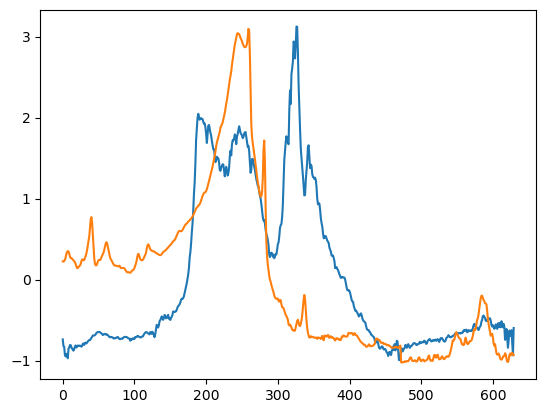

Polyamide 0.5911057546599433


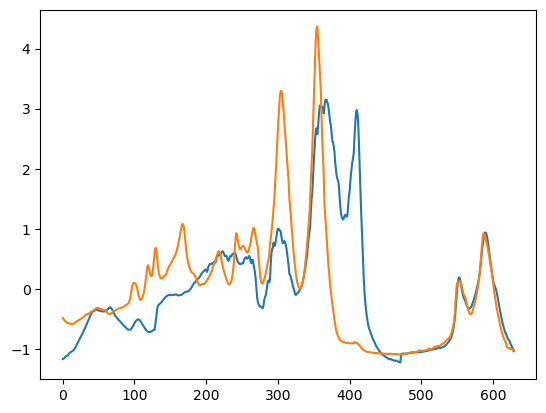

Polystyrene 0.7873446356336888


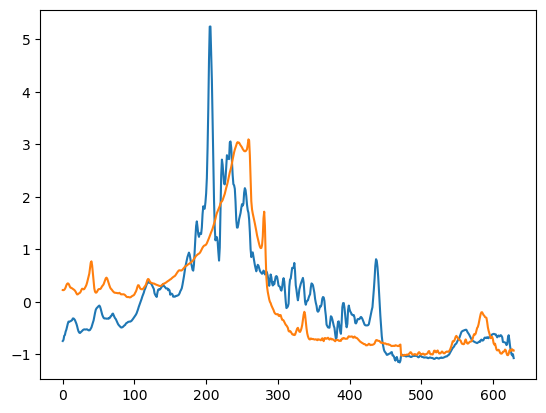

Rubber 0.6275918634897942


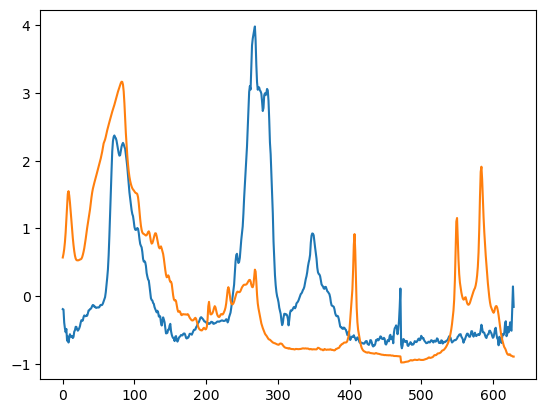

Rubber 0.7807714754758086


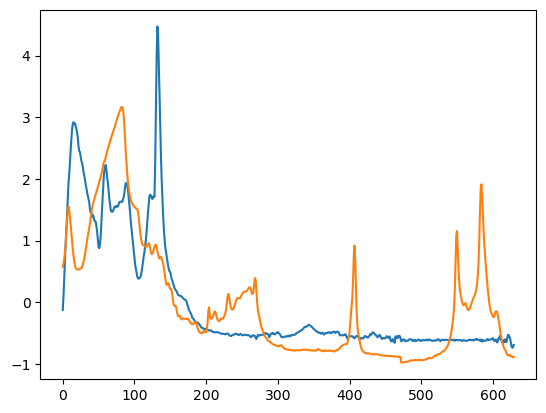

Polystyrene 0.6531284284930351


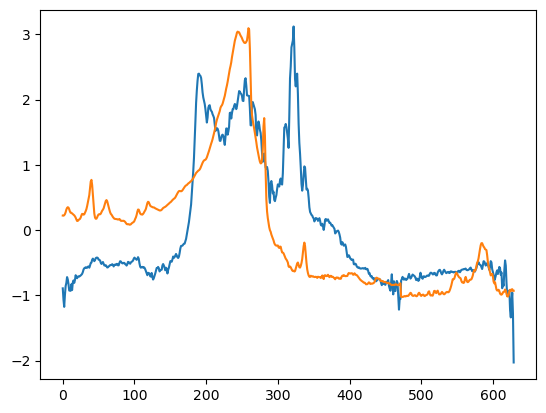

Polyethylene Vinyl Acetate 0.534858585592534


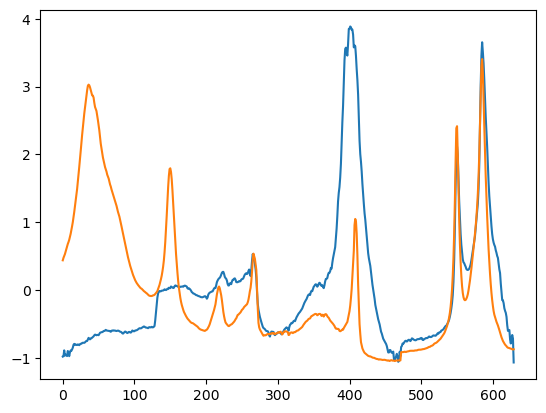

Polycarbonate 0.7148040224403293


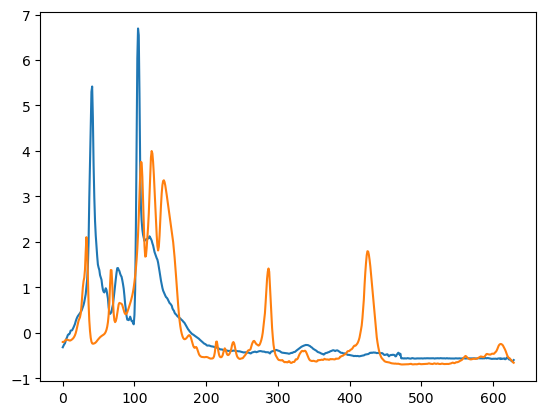

Rubber 0.5033395826055671


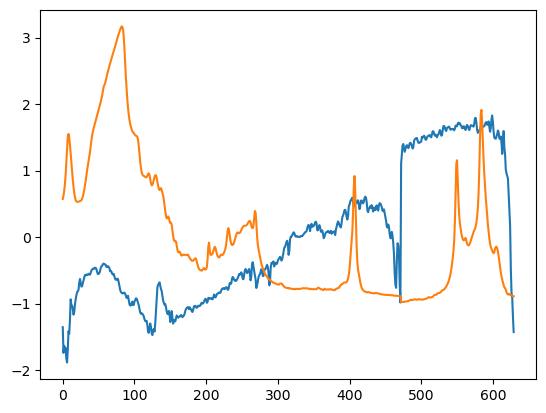

Polyethylene Vinyl Acetate 0.47676216202246297


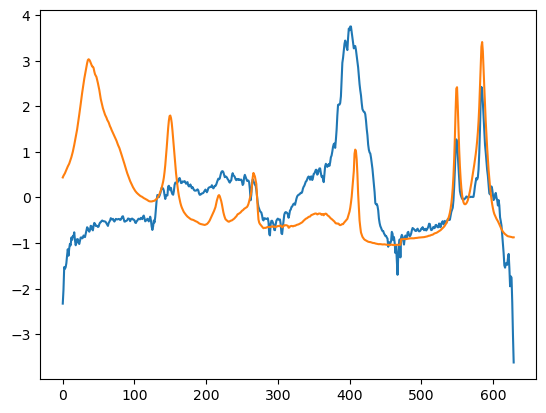

Polystyrene 0.708102903070585


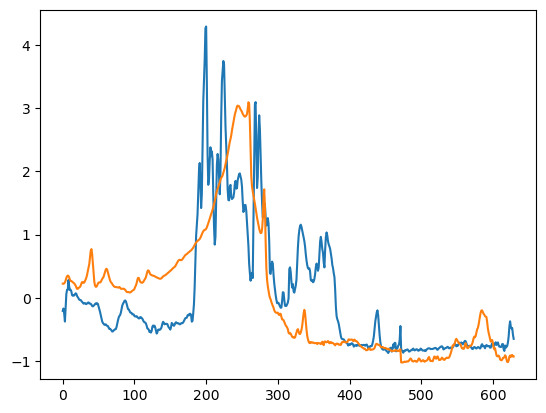

Polyethylene Vinyl Acetate 0.4601043323448649


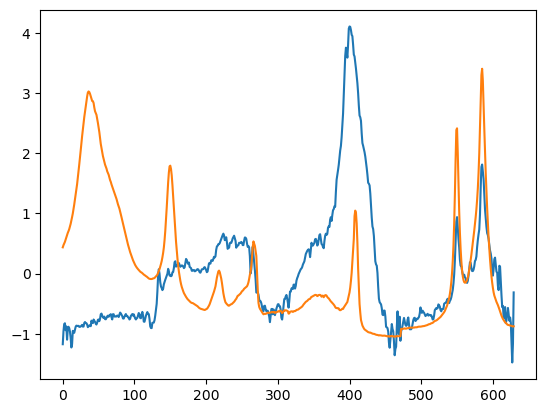

Rubber 0.4139291240566715


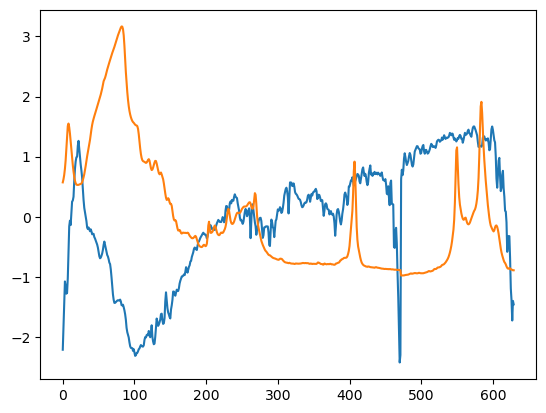

Polyamide 0.4167634999188364


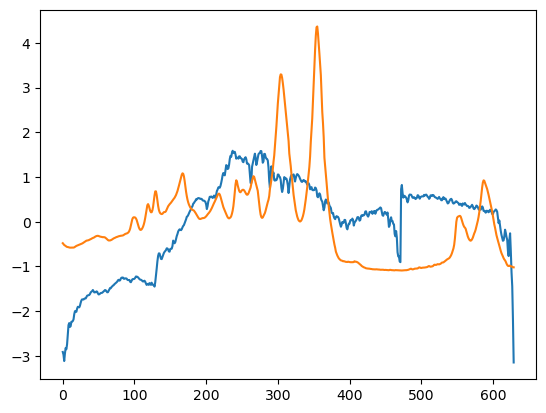

Polystyrene 0.7915109204200583


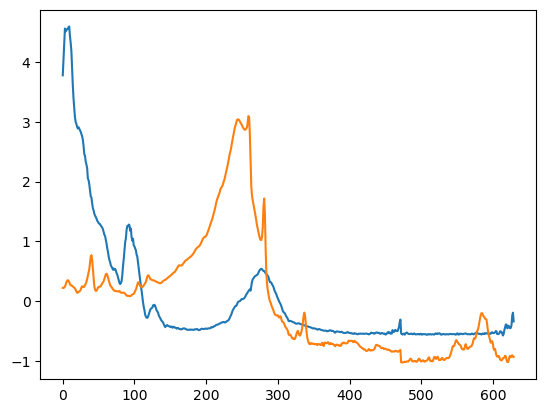

Polyethylene Vinyl Acetate 0.5259721921647227


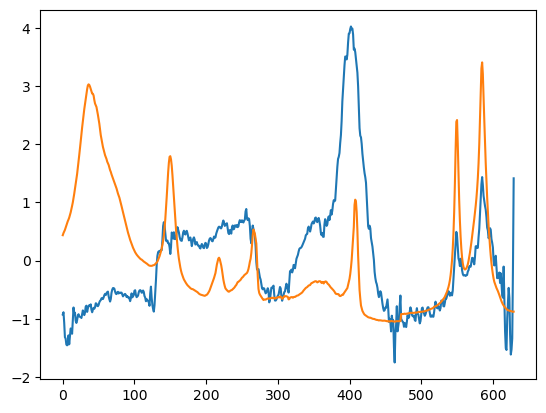

Cotton 0.7797857550538417


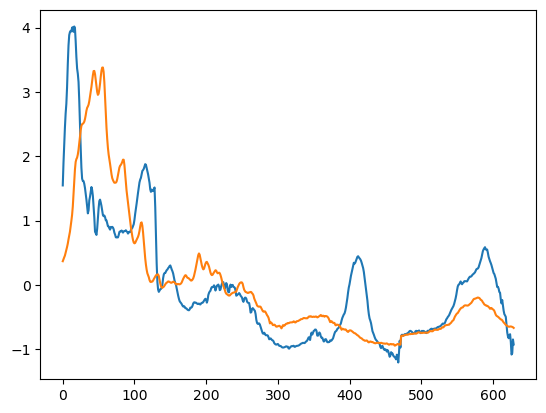

Polyamide 0.5546040312001445


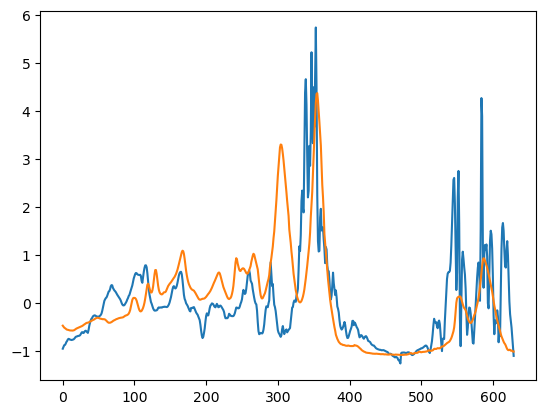

In [186]:
for i, s in enumerate(spectra_data_np_norm):
    if pred_hqi[i] >= .8:
        continue
    print(pred_polymers_hqi[i], pred_hqi[i])
    plt.plot(s)
    plt.plot(-x_train[y_train_ == pred_polymers_hqi[i]][0])
    #plt.plot(-X_train.loc[y_train_ == pred_poly[i],:].iloc[0,:].to_numpy())
    
    plt.show()

In [187]:
(pred_polymers_hqi == pred_poly).mean()

0.5428571428571428

In [188]:
pred_poly[1]

'Rubber'

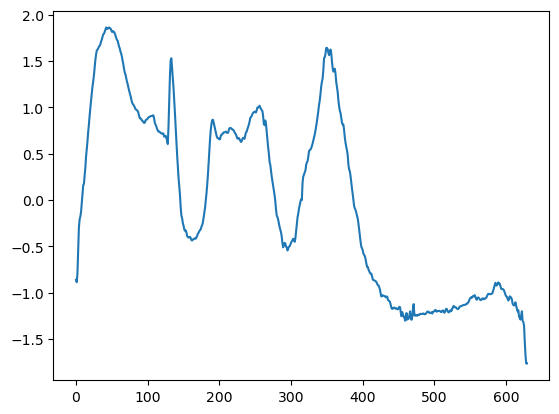

In [194]:
plt.plot(spectra_data_np_norm[15], label='sample')

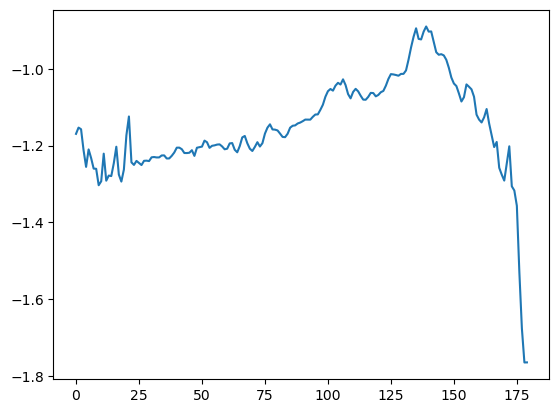

In [193]:
plt.plot(spectra_data_np_norm[15][450:], label='sample')

0
logistic regression: Cotton 64
                hqi: Polystyrene 89


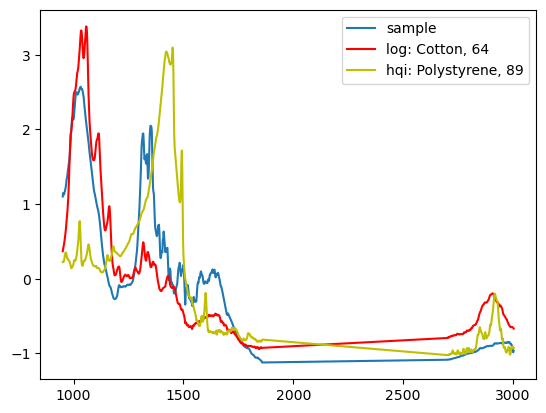

1
logistic regression: Rubber 47
                hqi: Rubber 96


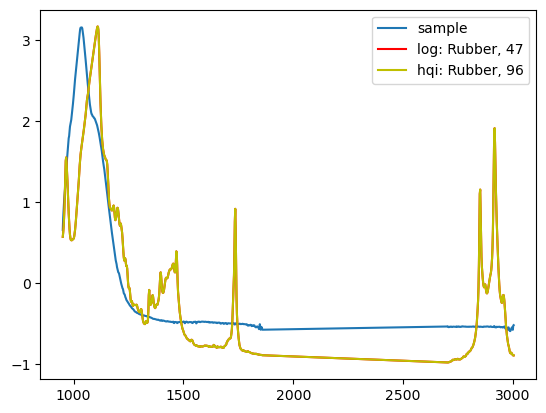

2
logistic regression: Polystyrene 71
                hqi: Polystyrene 84


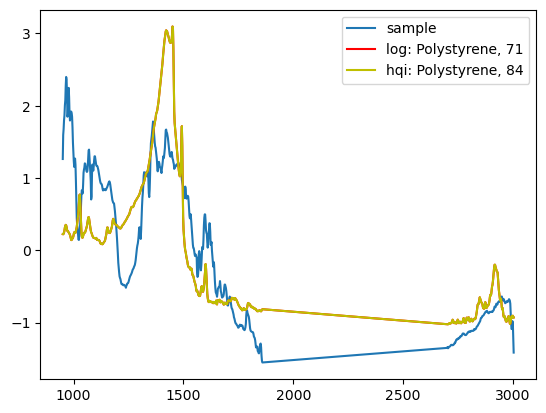

3
logistic regression: Rubber 43
                hqi: Polypropylene 87


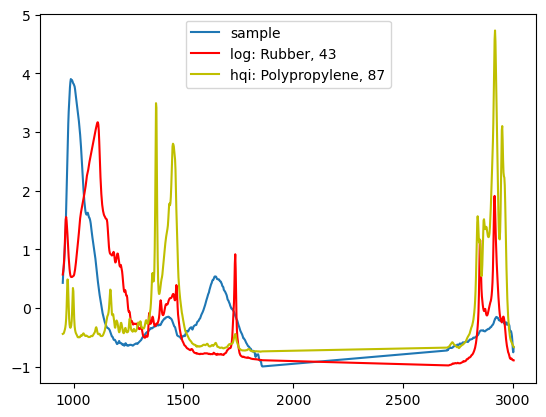

4
logistic regression: Polystyrene 97
                hqi: Polystyrene 79


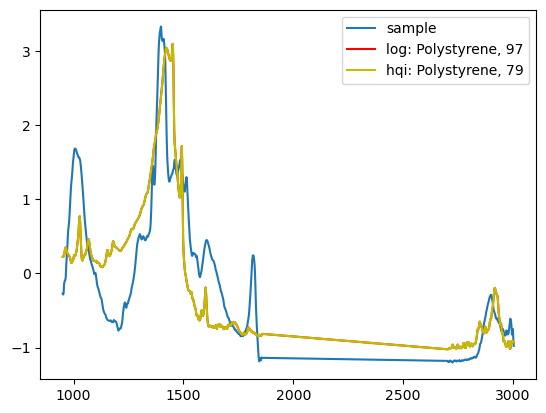

5
logistic regression: Polystyrene 85
                hqi: Polystyrene 69


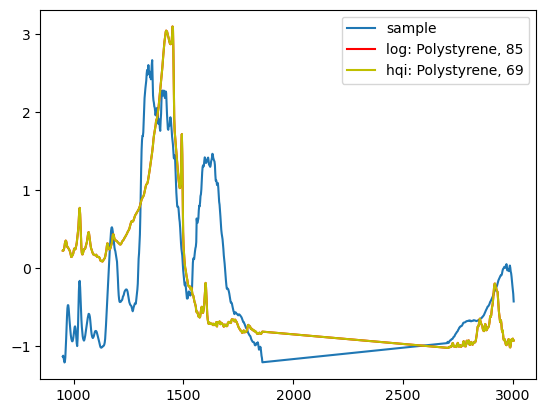

6
logistic regression: Cotton 62
                hqi: Polystyrene 87


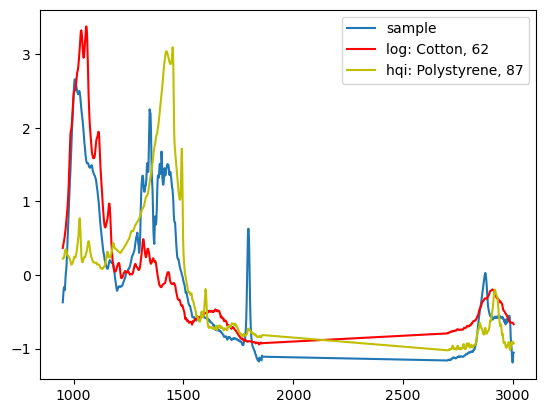

7
logistic regression: Polyethylene 39
                hqi: Polyamide 53


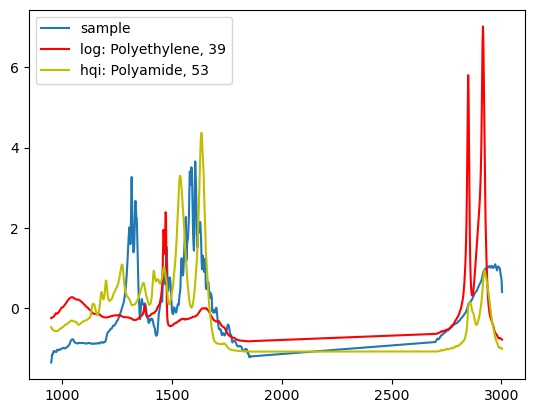

8
logistic regression: Polystyrene 93
                hqi: Polystyrene 67


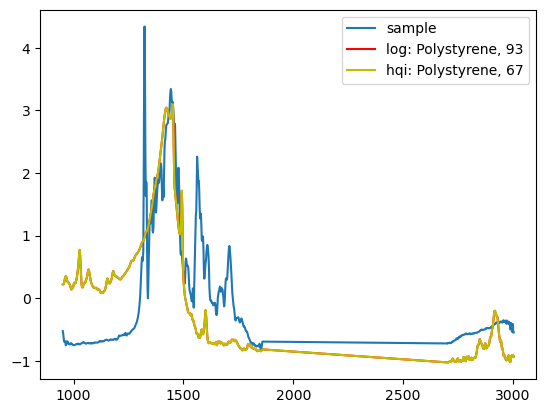

9
logistic regression: Polystyrene 77
                hqi: Polystyrene 65


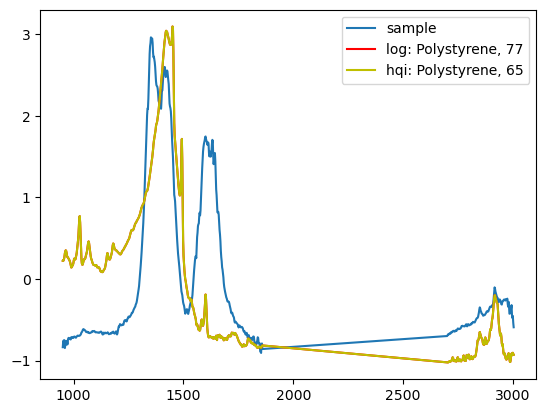

10
logistic regression: Polystyrene 84
                hqi: Polystyrene 67


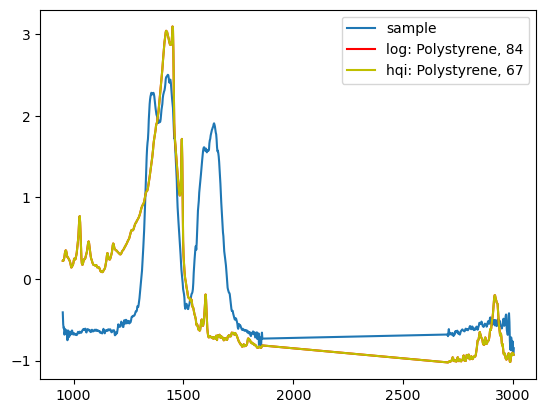

11
logistic regression: Rubber 80
                hqi: Rubber 97


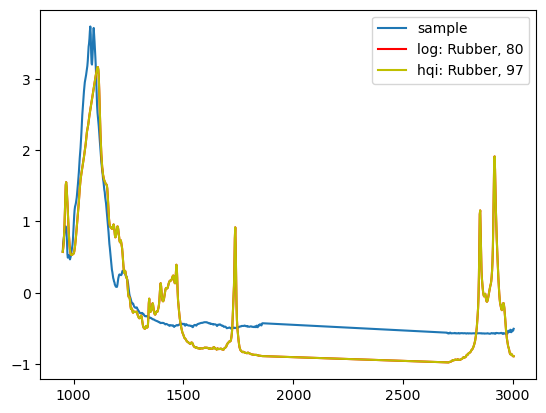

12
logistic regression: Rubber 31
                hqi: Cotton 85


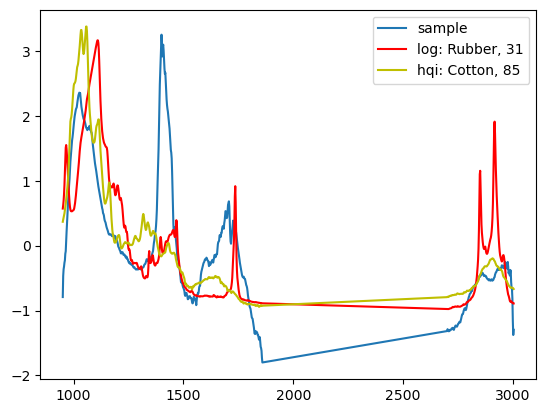

13
logistic regression: Polystyrene 61
                hqi: Polystyrene 89


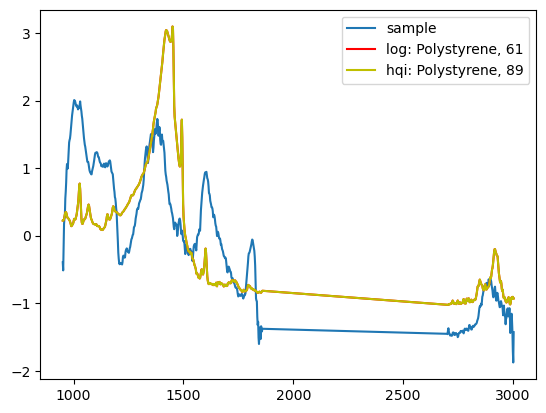

14
logistic regression: Polyethylene Vinyl Acetate 29
                hqi: Ethylene Acrylic Acid 79


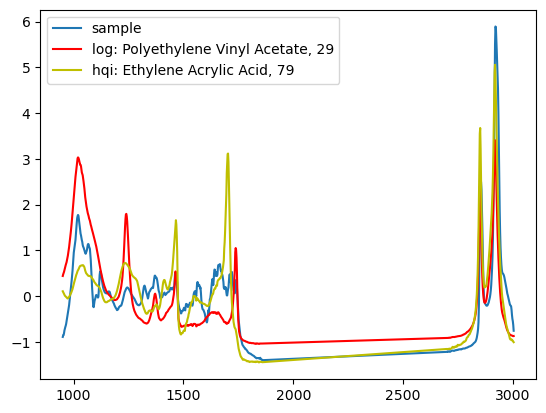

15
logistic regression: Polystyrene 37
                hqi: Polystyrene 89


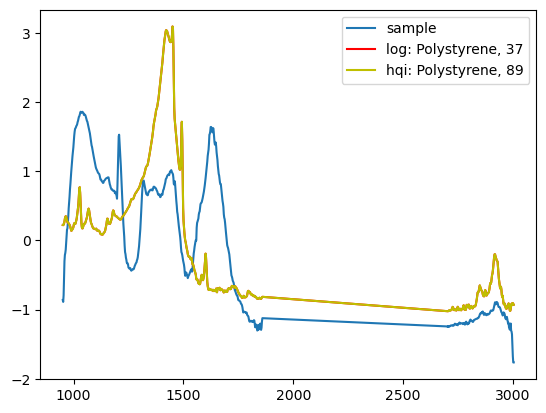

16
logistic regression: Rubber 72
                hqi: Cotton 93


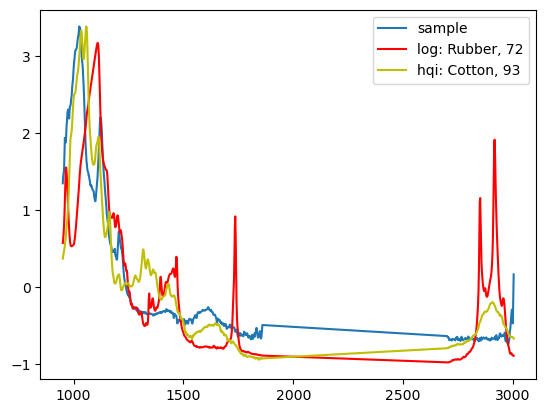

17
logistic regression: Polystyrene 81
                hqi: Polyurethane 84


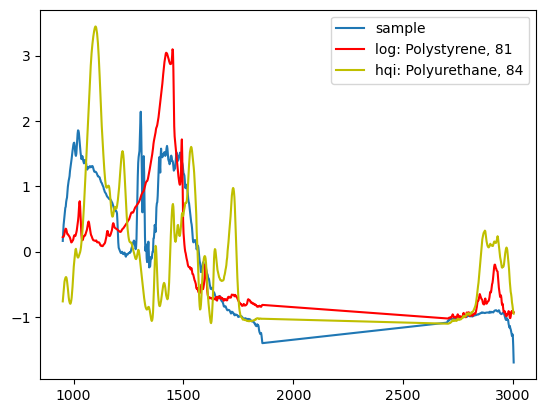

18
logistic regression: Cotton 69
                hqi: Rubber 87


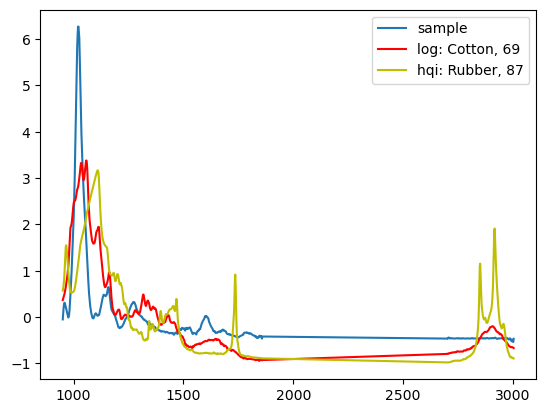

19
logistic regression: Polyethylene 30
                hqi: Polyethylene 90


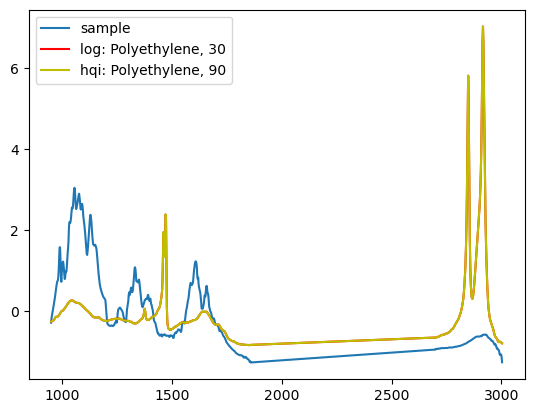

20
logistic regression: Polystyrene 94
                hqi: Polystyrene 90


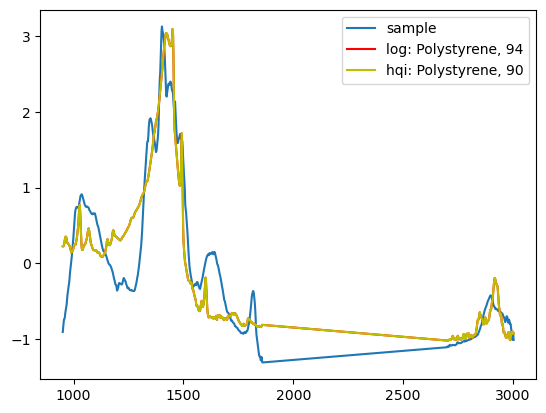

21
logistic regression: Rubber 91
                hqi: Cotton 92


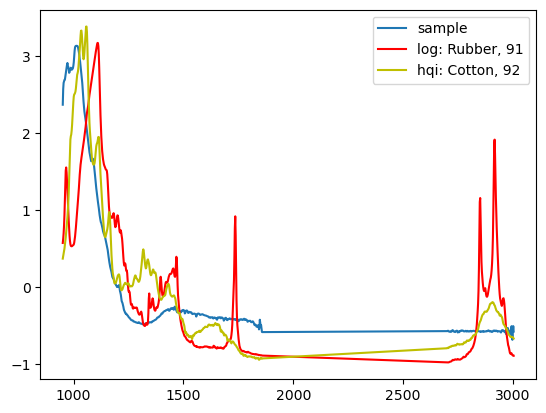

22
logistic regression: Polystyrene 90
                hqi: Polystyrene 87


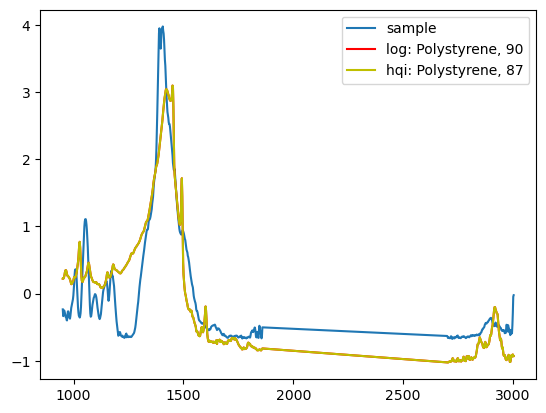

23
logistic regression: Rubber 81
                hqi: Polystyrene 86


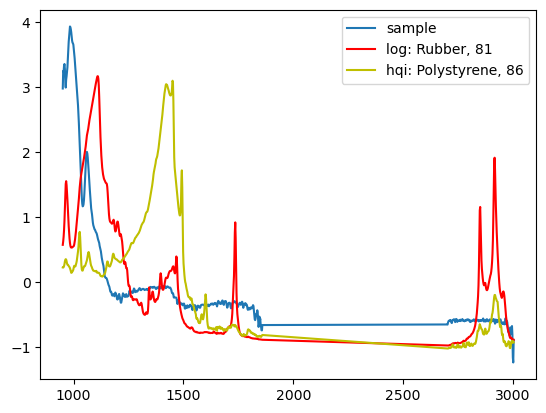

24
logistic regression: Rubber 42
                hqi: Rubber 75


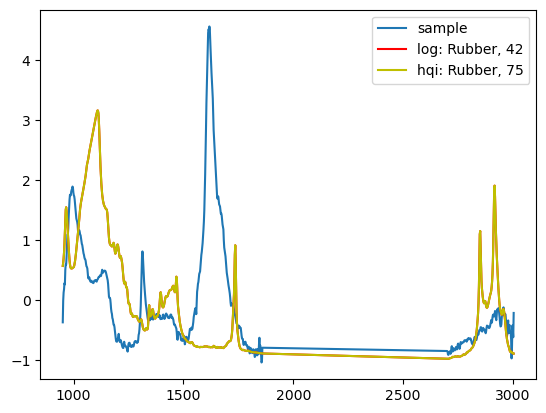

25
logistic regression: Polystyrene 61
                hqi: Polystyrene 67


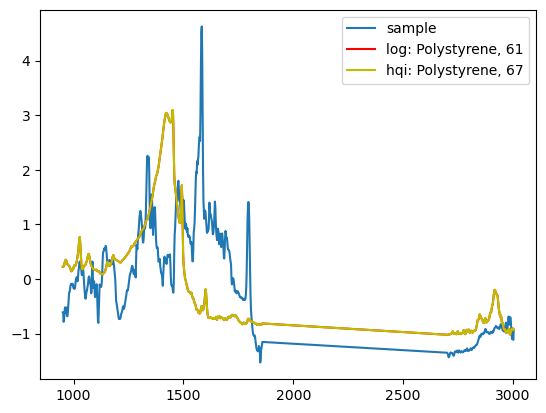

26
logistic regression: Rubber 39
                hqi: Rubber 89


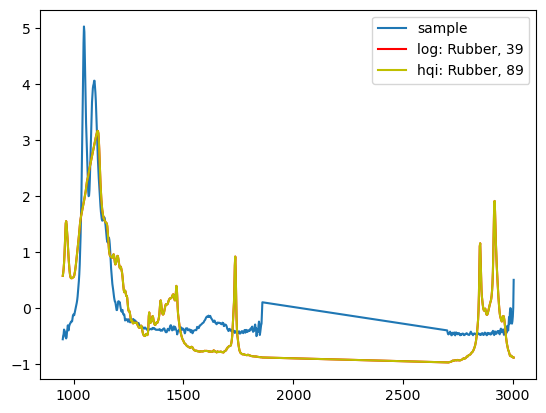

27
logistic regression: Rubber 38
                hqi: Rubber 93


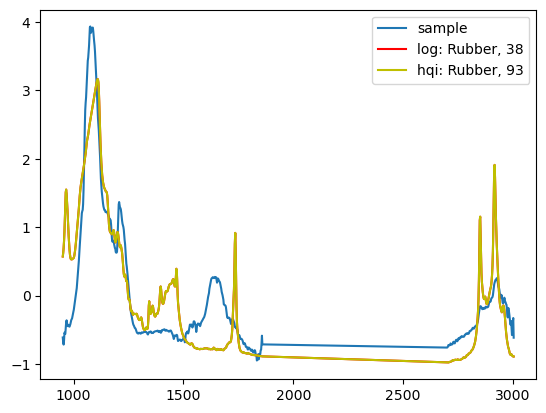

28
logistic regression: Polystyrene 87
                hqi: Polystyrene 65


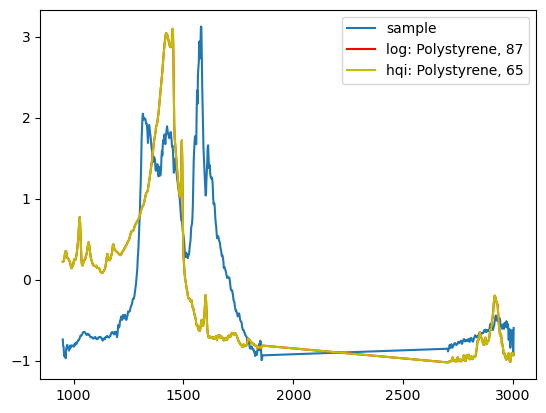

29
logistic regression: Rubber 79
                hqi: Polystyrene 89


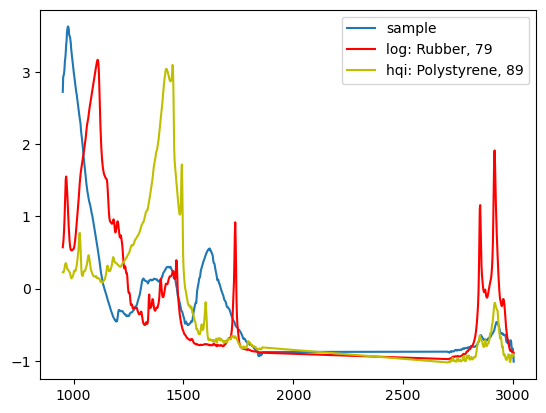

30
logistic regression: Polyamide 60
                hqi: Polyamide 59


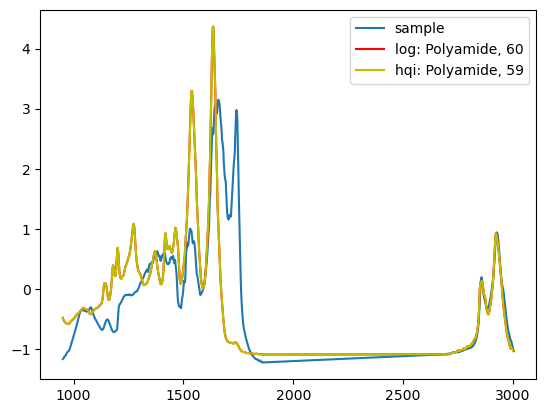

31
logistic regression: Polystyrene 78
                hqi: Polystyrene 79


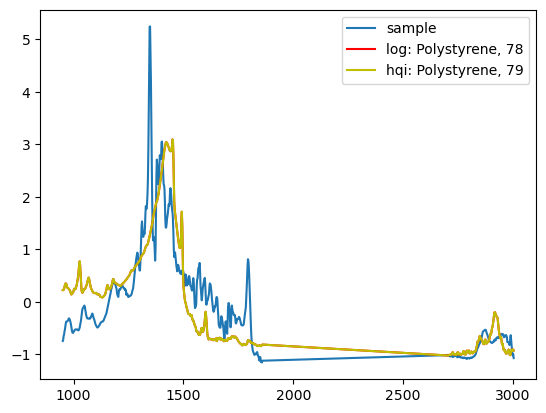

32
logistic regression: Rubber 37
                hqi: Rubber 63


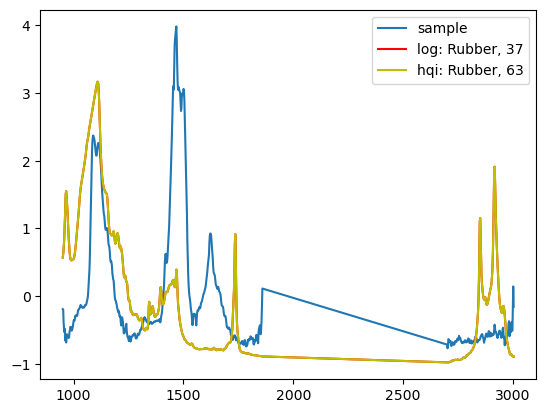

33
logistic regression: Rubber 70
                hqi: Rubber 78


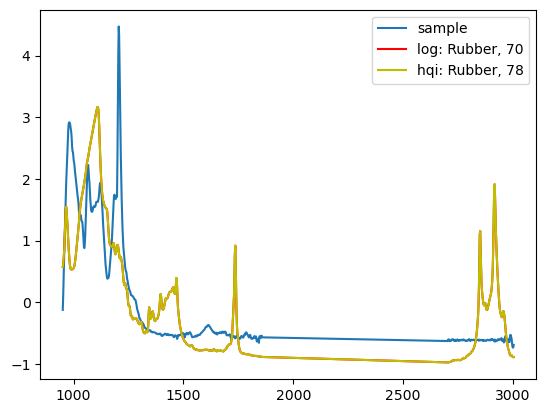

34
logistic regression: Polystyrene 93
                hqi: Polystyrene 65


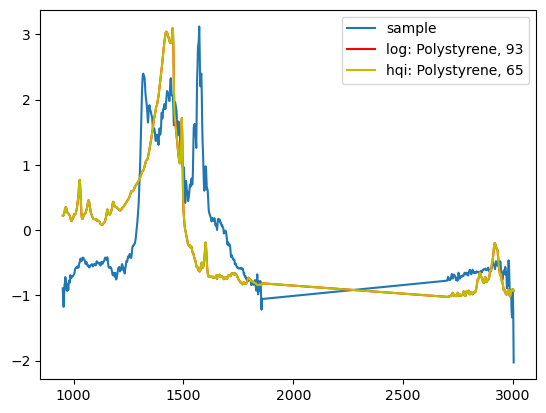

35
logistic regression: Rubber 58
                hqi: Cotton 85


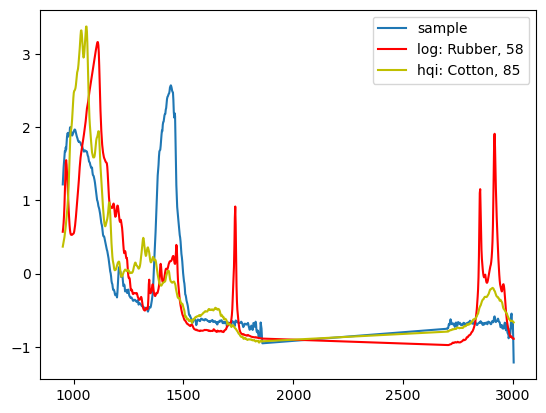

36
logistic regression: Ethylene Acrylic Acid 26
                hqi: Polyethylene Vinyl Acetate 53


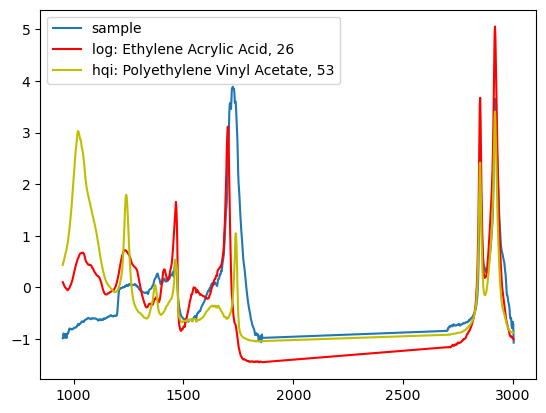

37
logistic regression: Cotton 32
                hqi: Polycarbonate 71


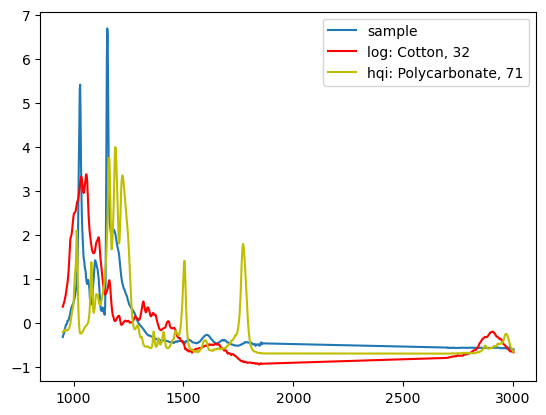

38
logistic regression: Polystyrene 92
                hqi: Polystyrene 84


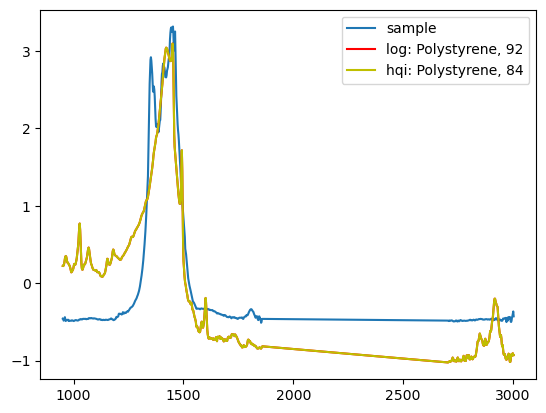

39
logistic regression: Rubber 81
                hqi: Rubber 91


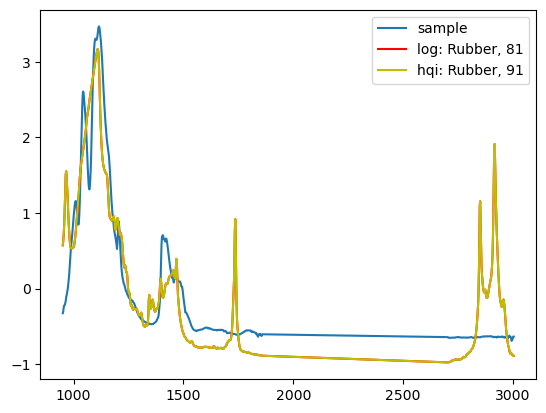

40
logistic regression: Rubber 54
                hqi: Rubber 50


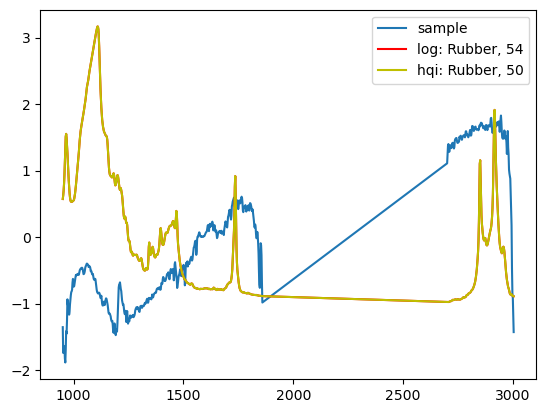

41
logistic regression: Polystyrene 89
                hqi: Polystyrene 83


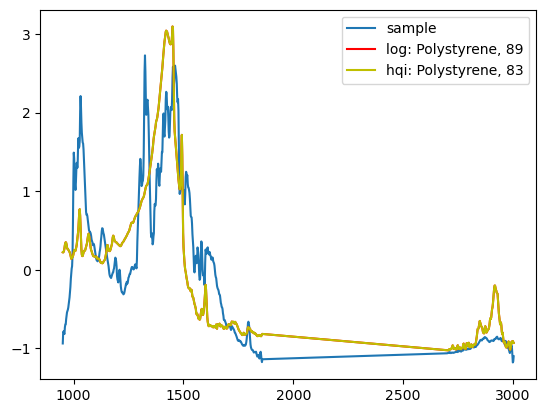

42
logistic regression: Rubber 77
                hqi: Cotton 92


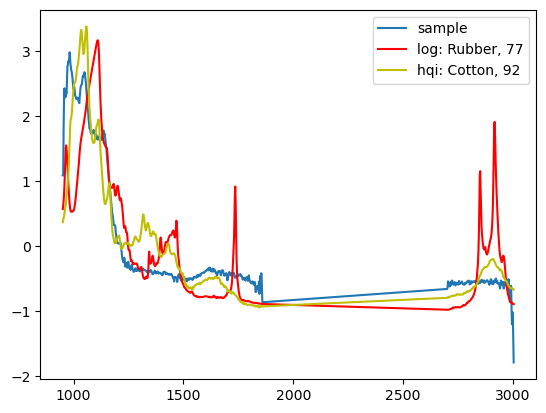

43
logistic regression: Polystyrene 93
                hqi: Polystyrene 83


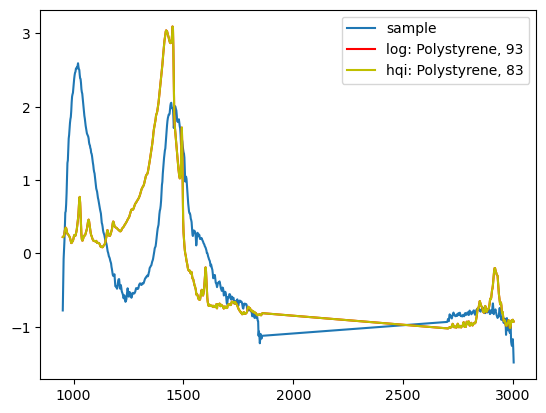

44
logistic regression: Rubber 96
                hqi: Rubber 87


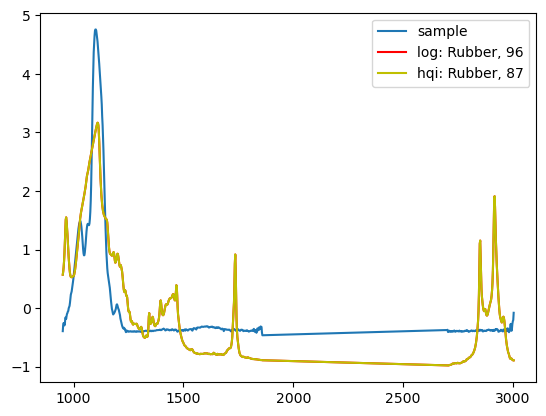

45
logistic regression: Cotton 70
                hqi: Cotton 94


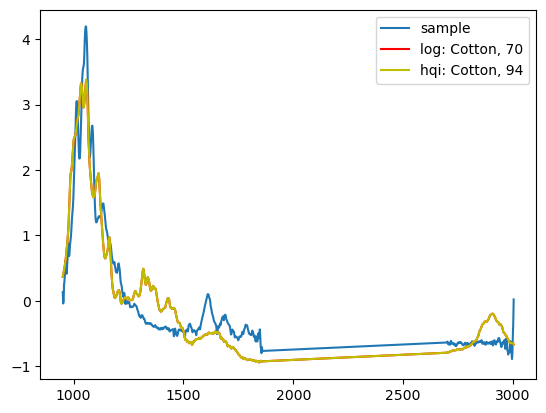

46
logistic regression: Polyethylene Terephthalate 36
                hqi: Polyethylene Vinyl Acetate 48


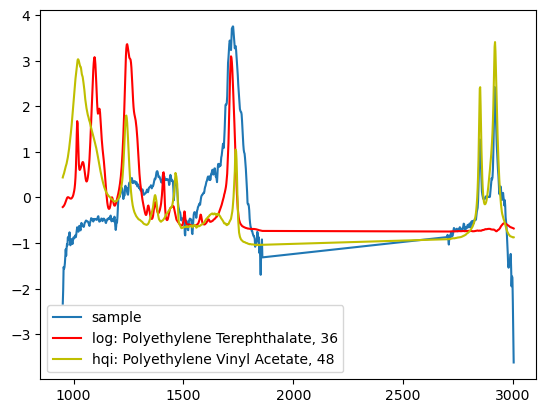

47
logistic regression: Cotton 90
                hqi: Cotton 97


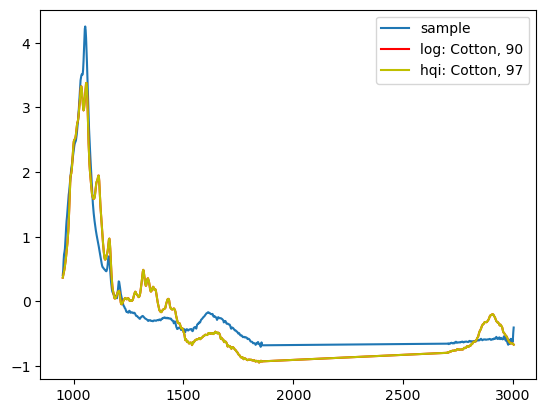

48
logistic regression: Polystyrene 92
                hqi: Polystyrene 71


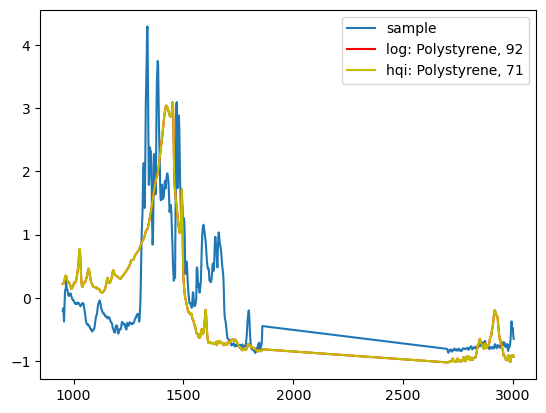

49
logistic regression: Polyethylene Terephthalate 36
                hqi: Polyethylene Vinyl Acetate 46


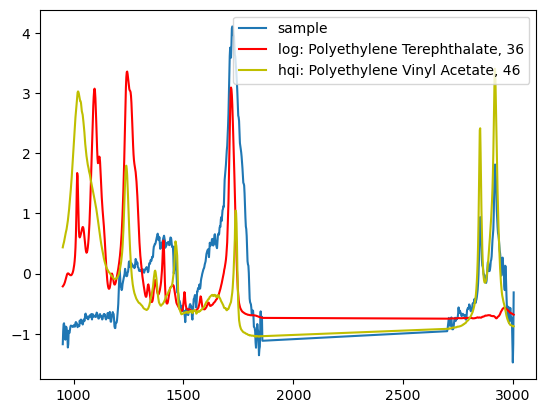

50
logistic regression: Polypropylene 53
                hqi: Rubber 41


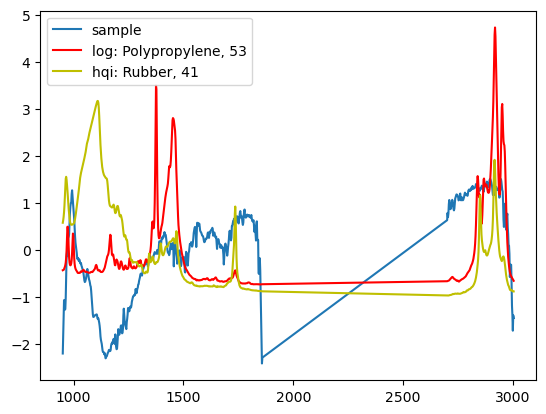

51
logistic regression: Rubber 92
                hqi: Rubber 90


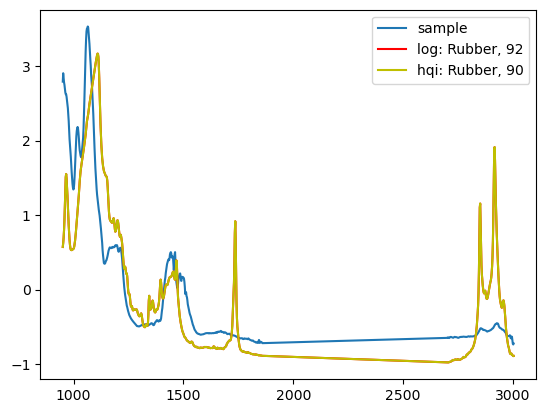

52
logistic regression: Cotton 56
                hqi: Rubber 80


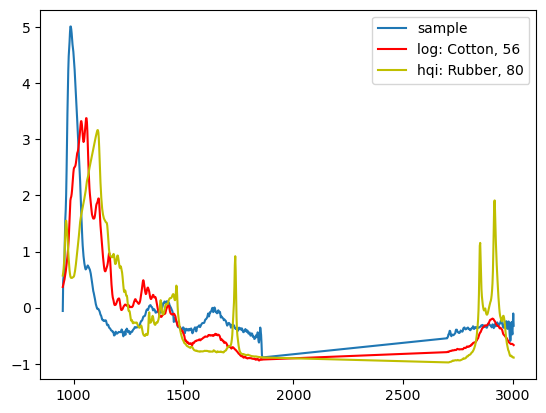

53
logistic regression: Polystyrene 55
                hqi: Polyamide 42


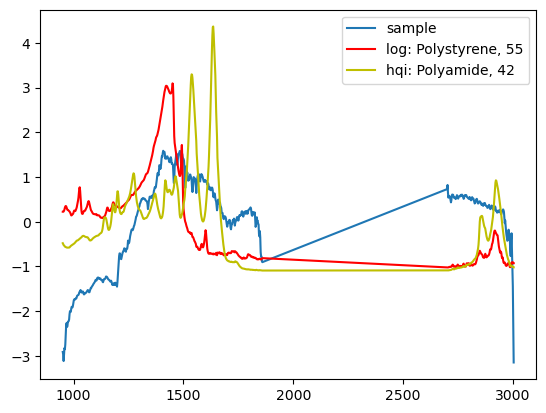

54
logistic regression: Rubber 63
                hqi: Rubber 95


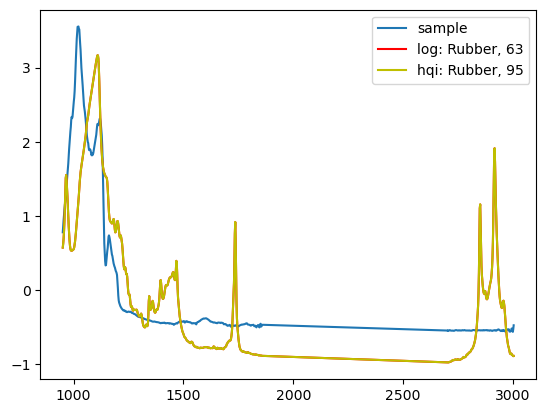

55
logistic regression: Polystyrene 94
                hqi: Polystyrene 88


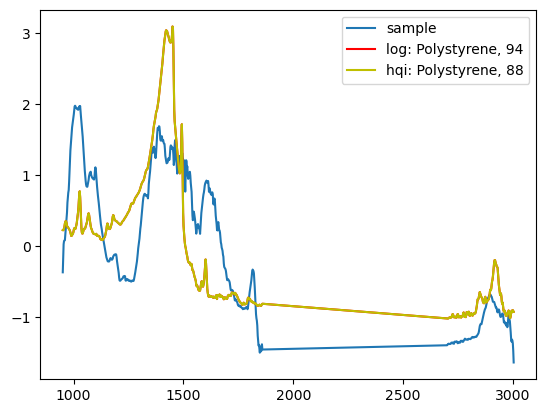

56
logistic regression: Polystyrene 93
                hqi: Polystyrene 84


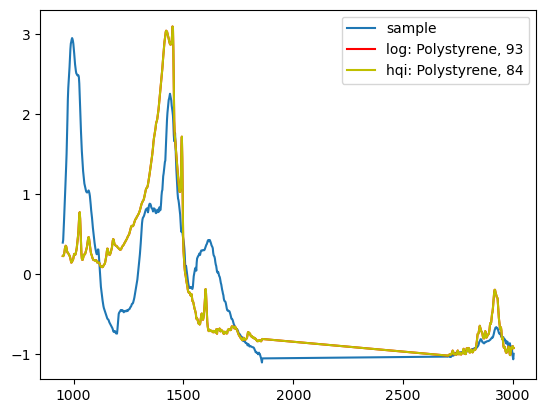

57
logistic regression: Polystyrene 72
                hqi: Rubber 87


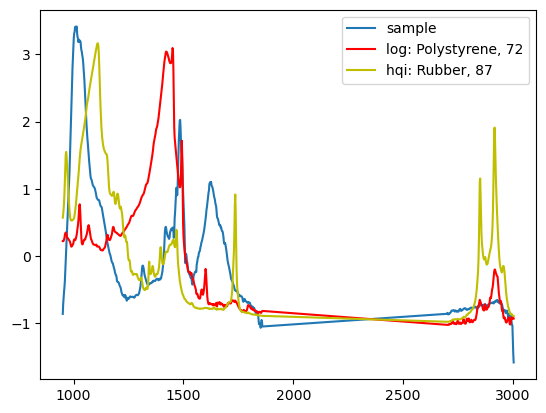

58
logistic regression: Cotton 37
                hqi: Polyethylene 89


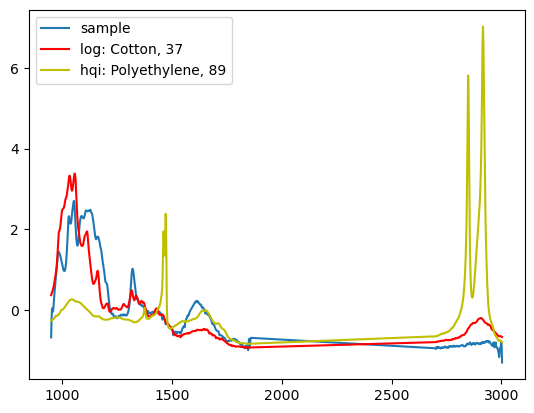

59
logistic regression: Rubber 87
                hqi: Polystyrene 91


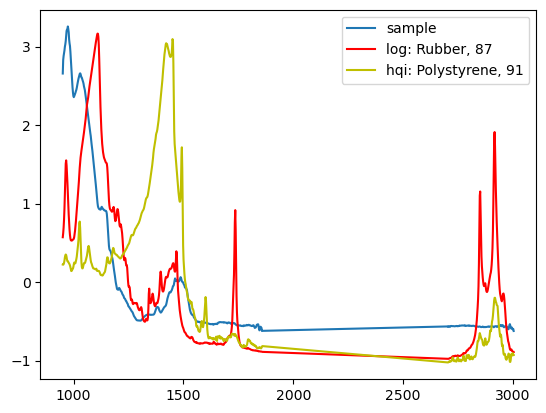

60
logistic regression: Rubber 57
                hqi: Polystyrene 86


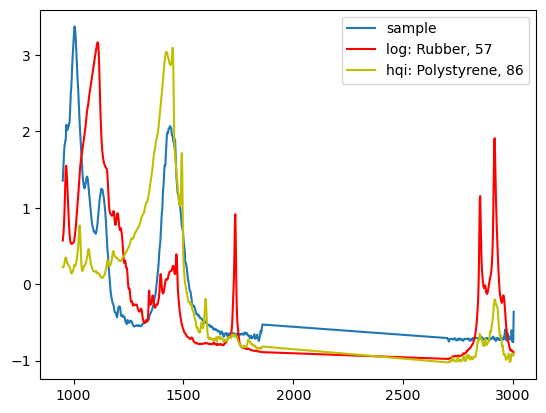

61
logistic regression: Rubber 98
                hqi: Polystyrene 79


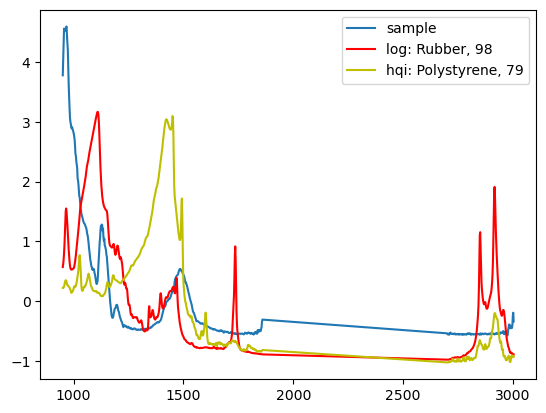

62
logistic regression: Polystyrene 52
                hqi: Polystyrene 85


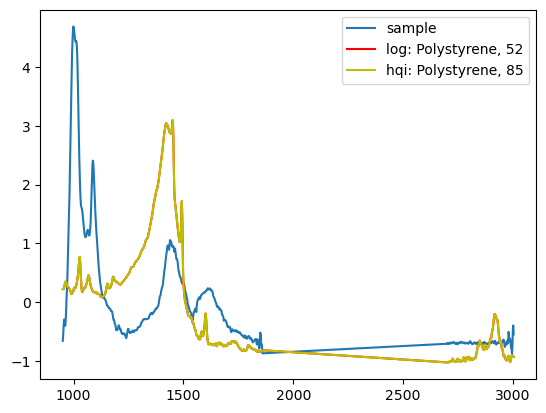

63
logistic regression: Rubber 52
                hqi: Cotton 96


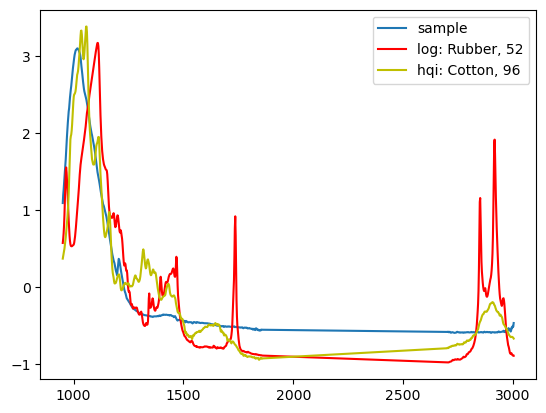

64
logistic regression: Rubber 88
                hqi: Polystyrene 90


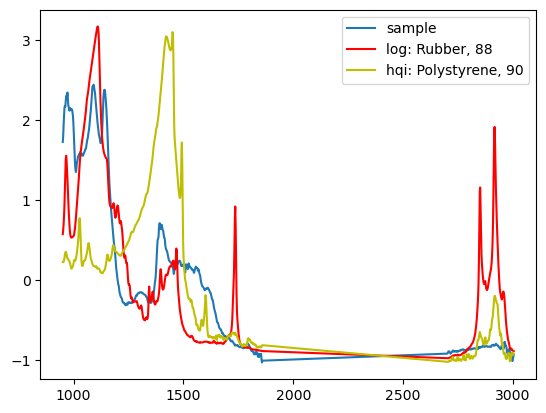

65
logistic regression: Rubber 86
                hqi: Polystyrene 94


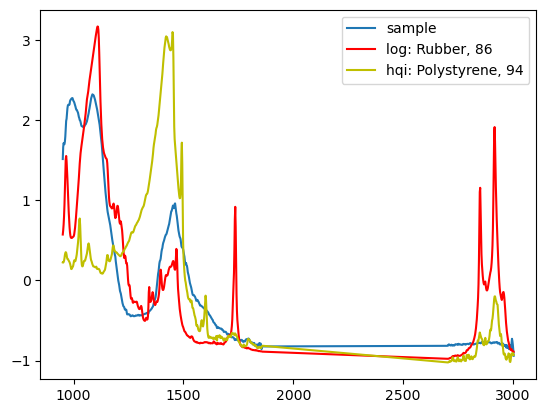

66
logistic regression: Polyethylene Terephthalate 50
                hqi: Polyethylene Vinyl Acetate 53


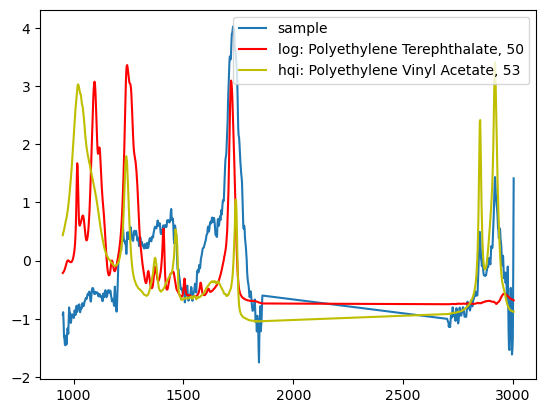

67
logistic regression: Rubber 78
                hqi: Rubber 93


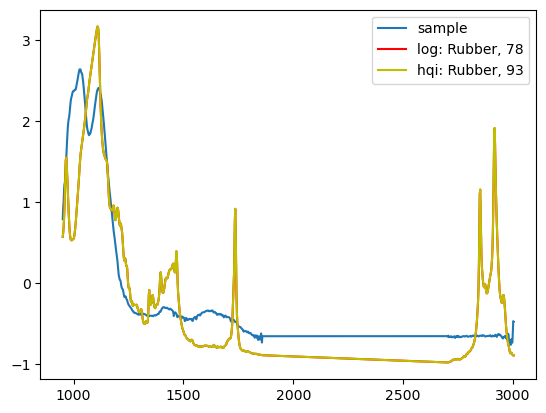

68
logistic regression: Rubber 74
                hqi: Cotton 78


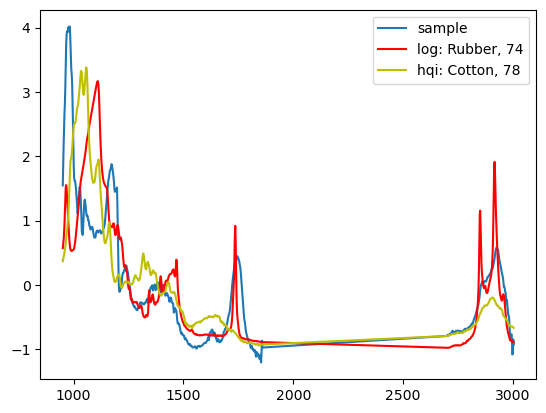

69
logistic regression: Polyethylene 40
                hqi: Polyamide 55


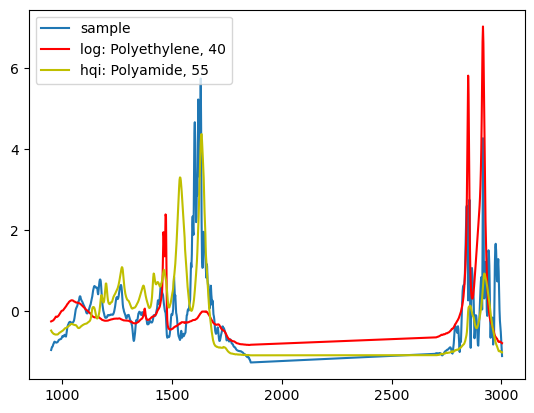

In [231]:
for i, s in enumerate(spectra_data_np_norm):
    #print(pred_poly[i], pred_prob[i])
    print(i)
    print('logistic regression: ' + pred_poly[i], round(pred_prob[i]*100))
    print('                hqi: ' + pred_polymers_hqi[i], round(pred_probs_hqi[i]*100))
    plt.plot((wl_list[idx_range]),s, label='sample')
    plt.plot((wl_list[idx_range]), -x_train[y_train_ == pred_poly[i]][0], c='r', label='log: ' + pred_poly[i] + ', ' + str(round(pred_prob[i]*100)))
    plt.plot((wl_list[idx_range]), -x_train[y_train_ == pred_polymers_hqi[i]][0], c='y', label='hqi: ' + pred_polymers_hqi[i]+ ', ' + str(round(pred_probs_hqi[i]*100)))
#    plt.plot(                     -X_train.loc[y_train_ == pred_poly[i],:].iloc[0,:].to_numpy())
    plt.legend()
    plt.savefig('MEC_02_066_results/sample_' + str(i) +'.png')
    plt.show()

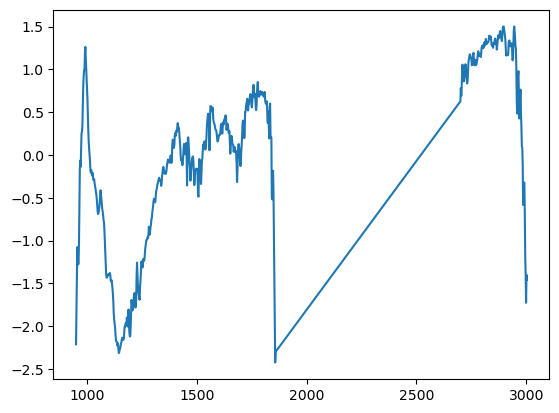

In [200]:
_ = plt.plot((wl_list[idx_range]), spectra_data_np_norm[pred_poly == 'Polypropylene'].T)

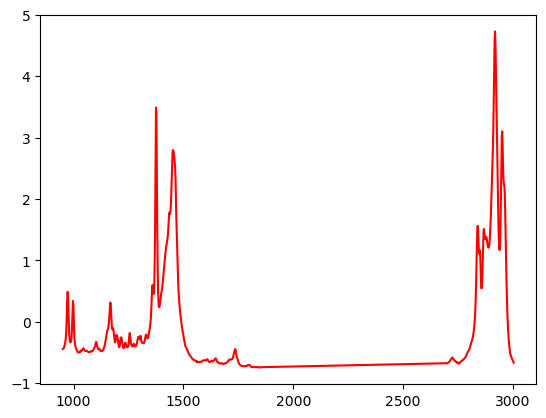

In [196]:

plt.plot((wl_list[idx_range]), -x_train[y_train_ == 'Polypropylene'][0], c='r', label='log')